# Notebook 02 — Análise comparativa: referência (normal) vs. anomalia

**O que buscamos aqui:** no Notebook 01 entendemos cada base. Agora queremos saber **o que muda de uma condição para outra, velocidade por velocidade**, e se essa mudança é **maior do que a variação natural do próprio normal**. Quatro perguntas:

1. Como o sinal e as features de tempo mudam do normal para a anomalia?
2. Quais frequências (faixas de 10 Hz) mudam, em qual eixo e em que direção?
3. A rotação (1X) e suas harmônicas mudam? A rotação é a mesma nas duas condições?
4. Quais features separam melhor as duas condições, e essa separação supera a variação natural do normal?

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configurar parâmetros | Escolher a condição de referência e o que será comparado |
| 2 | Carregar as bases | As mesmas bases do Notebook 01 e a lista de comparações |
| 3 | Cortar em janelas e calcular as 99 features | A mesma tabela de features do dataset, mais o espectro de cada janela |
| 4 | Sinal no tempo, referência sobre anomalia | Ver a diferença de amplitude e de forma da onda |
| 5 | Features de tempo (desvio padrão, curtose e pico) | Quais mudam, para que lado, e quanto separam |
| 6 | Espectro médio, referência sobre anomalia | Em quais frequências a anomalia aparece |
| 7 | Mapa por faixa de 10 Hz | Onde, em qual eixo e em que direção cada faixa muda |
| 8 | Rotação 1X e harmônicas | A rotação mudou? 1X, 2X e 3X cresceram? |
| 9 | Resumo e controle | As melhores features e o teto de variação natural do normal |

## Sobre os dados desta versão (dados novos)

Esta é a versão do Notebook 02 para os **dados novos** (pasta `NOVOS_DADOS`): uma bateria de testes com a oscilação ligada, com **normal, fita 1g, papel e porca frouxa** nas três velocidades. Cada teste começou com o motor frio, então as gravações carregam o **aquecimento** (Notebook 01). As três falhas são comparadas com o normal automaticamente, e o **Passo 10** (novo) compara as falhas entre si.

Como no Notebook 01, os primeiros e os últimos `DESCARTAR_INICIO_S`/`DESCARTAR_FIM_S` segundos de cada base são descartados (falhas de leitura do sensor ao ligar a gravação).

## Como usar

1. Use a mesma pasta de bases do Notebook 01 (`<condicao>_vel_<N>.csv`, um arquivo por condição e velocidade).
2. No Passo 1, diga quais condições são a **referência** (por exemplo, `["ventilador_normal"]`). **Todas as outras condições da pasta são comparadas com ela automaticamente.** Condições novas (como `desbalanceamento_1g` ou `atrito`) entram sozinhas, sem mudar o código.
3. Se houver várias rodadas de Normal, coloque todas na lista de referência. Elas entram juntas, em cada velocidade. Para checar a **deriva entre duas rodadas de Normal**, coloque uma na referência e a outra em `CONDICOES_COMPARADAS`.

## Como ler a "separação"

Várias comparações usam a **separação**, um número de **−1 a +1** calculado para cada feature e cada velocidade:

* **0:** as janelas da anomalia e as da referência estão misturadas, sem diferença.
* **+1:** **todas** as janelas da anomalia têm valor maior que **todas** as da referência.
* **−1:** todas as janelas da anomalia têm valor menor.

Ela se baseia em posições (ranks) e não supõe distribuição normal, o que importa porque o Shapiro-Wilk mostrou que poucas features são normais. **Cuidado:** janelas vizinhas são parecidas entre si (autocorrelação), então a separação é um guia visual e **não** um teste estatístico. O teste vem no Notebook 03.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. A escolha mais importante é a **condição de referência**, o ponto de comparação de todo o notebook.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import kurtosis, rankdata
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta do Notebook 01)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS")
BUSCAR_EM_SUBPASTAS = True        # True = lê também os CSVs dentro das subpastas (NORMAL, ANOMALIA)
DESCARTAR_INICIO_S = 5            # segundos descartados no começo de cada base (Notebook 01, Passo 4.1)
DESCARTAR_FIM_S = 5               # segundos descartados no fim de cada base

# ----------------------------------------------------------------------
# QUEM É REFERÊNCIA E QUEM É COMPARADO
# ----------------------------------------------------------------------
CONDICOES_REFERENCIA = ["ventilador_normal"]   # use o prefixo do nome do arquivo; várias rodadas entram juntas
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do dataset de 99 features)
# ----------------------------------------------------------------------
JANELA_S = 5                      # janela de 5 s, sem sobreposição
FAIXA_FFT_HZ = (5, 305)           # faixas de 10 Hz de 5 a 305 Hz
LARGURA_FAIXA_HZ = 10

# ----------------------------------------------------------------------
# GRÁFICOS
# ----------------------------------------------------------------------
INICIO_TRECHO_S = None            # onde começa o trecho de 1 s do Passo 4 (None = meio de cada base)
F_MAX_PLOT_HZ = 300               # limite superior do espectro do Passo 6
ESCALA_Y_FFT = "linear"           # "linear" ou "log" (a log destaca diferenças em picos pequenos)

# ----------------------------------------------------------------------
# ROTAÇÃO 1X E HARMÔNICAS (Passo 8)
# ----------------------------------------------------------------------
FAIXA_BUSCA_1X_HZ = (8, 30)       # faixa onde procuramos o pico de rotação (ajuste se mudar o ventilador)
DESVIO_MAX_1X_HZ = 2.0            # numa janela, o 1X só pode ficar a até esta distância da rotação típica da base
N_HARMONICAS = 3                  # mede 1X, 2X e 3X
TOLERANCIA_HARMONICA_HZ = 0.6     # a amplitude de kX é o maior pico a até esta distância de k vezes o 1X

# ----------------------------------------------------------------------
# RESUMO (Passo 9)
# ----------------------------------------------------------------------
N_TOP = 5                         # quantas features mostrar por velocidade

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
COR_REFERENCIA = "dodgerblue"
COR_COMPARADA = "crimson"
NOMES_EIXOS = {"x": "Eixo X (lateral)", "y": "Eixo Y (frontal)", "z": "Eixo Z (vertical)"}

## Passo 2 — Carregar as bases e definir as comparações

**O que buscamos:** ler a pasta (as funções são as mesmas do Notebook 01) e montar a **lista de comparações**: cada condição comparada contra a referência, velocidade por velocidade.

Em seguida, uma tabela mostra quantas bases e quantos segundos existem por condição e velocidade. Confira se **toda velocidade comparada também existe na referência**. Sem isso não há com o que comparar.

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo



def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base (o mesmo corte do Notebook 01)."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo


def definir_comparacoes(catalogo, condicoes_referencia, condicoes_comparadas=None):
    """Confere a referência e devolve a lista de condições que serão comparadas com ela."""
    existentes = sorted(catalogo["condicao"].unique())
    faltando = [c for c in condicoes_referencia if c not in existentes]
    if faltando:
        raise ValueError(f"Condição de referência não encontrada: {faltando}. Condições na pasta: {existentes}")
    if condicoes_comparadas is None:
        condicoes_comparadas = [c for c in existentes if c not in condicoes_referencia]
    faltando = [c for c in condicoes_comparadas if c not in existentes]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Condições na pasta: {existentes}")
    if not condicoes_comparadas:
        raise ValueError(
            "Não há nenhuma condição para comparar com a referência. "
            "Coloque na pasta as bases da anomalia (por exemplo fita_1g_vel_1.csv)."
        )
    return list(condicoes_comparadas)


def resumir_catalogo(catalogo):
    """Número de bases e total de segundos por condição e velocidade."""
    return catalogo.groupby(["condicao", "velocidade"]).agg(bases=("linhas", "size"), duracao_s=("duracao_s", "sum"))


def avisar_velocidades_sem_referencia(catalogo, condicoes_referencia, condicoes_comparadas):
    """Avisa quando uma condição comparada tem uma velocidade que a referência não tem."""
    velocidades_ref = set(catalogo.loc[catalogo["condicao"].isin(condicoes_referencia), "velocidade"])
    for condicao in condicoes_comparadas:
        velocidades = set(catalogo.loc[catalogo["condicao"] == condicao, "velocidade"])
        sem_ref = sorted(velocidades - velocidades_ref)
        if sem_ref:
            print(f"ATENÇÃO: '{condicao}' tem as velocidades {sem_ref}, que a referência não tem. Elas ficarão sem comparação.")

In [4]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
bases, catalogo = aparar_bases(bases, catalogo)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_REFERENCIA, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Referência: {CONDICOES_REFERENCIA}")
print(f"Comparadas: {condicoes_comparadas}")
avisar_velocidades_sem_referencia(catalogo, CONDICOES_REFERENCIA, condicoes_comparadas)
display(resumir_catalogo(catalogo))

Referência: ['ventilador_normal']
Comparadas: ['fita_1g', 'papel', 'porca_frouxa']


bases  duracao_s
condicao          velocidade                  
fita_1g           1               1    619.500
                  2               1    647.000
                  3               1    633.500
papel             1               1    629.000
                  2               1    633.000
                  3               1    642.500
porca_frouxa      1               1    638.000
                  2               1    638.492
                  3               1    640.500
ventilador_normal 1               1    636.000
                  2               1    647.500
                  3               1    623.500

### O que encontramos (dados novos)

* **12 bases**, uma por condição e velocidade: normal, fita 1g, papel e porca frouxa, cada uma nas Vel 1, 2 e 3. Depois do corte de 5 s no começo e no fim, cada base tem entre **619,5 s e 647,5 s**.
* A referência é o **ventilador normal** e as três falhas entraram como comparadas automaticamente (`CONDICOES_COMPARADAS = None`).
* **Atenção para o resto do notebook:** existe **uma única gravação** por condição e velocidade. Então, quando duas condições se separam, não dá para saber só com este notebook se a diferença vem da falha ou da gravação (montagem, temperatura, dia). Esse risco é tratado no Notebook 05, com o teste em outra sessão.

## Passo 3 — Cortar em janelas e calcular as 99 features

**O que buscamos:** transformar cada base na **tabela de features** que o dataset do grupo usa, para comparar condições em números e não só a olho.

Cada base é cortada em janelas de `JANELA_S` segundos, sem sobreposição. Em cada janela, depois de remover o componente DC (a gravidade), calculamos:

* **9 features de tempo:** desvio padrão (`std`), curtose de Fisher (`kurt`) e pico (`pico`, o maior valor absoluto), por eixo.
* **90 features de frequência:** FFT com janela de Hanning, dividida em faixas de 10 Hz de 5 a 305 Hz. O valor de cada faixa é o **máximo** da magnitude dentro dela, por eixo (`fft_005_015Hz_x` etc.).

Guardamos também o **espectro completo de cada janela**. Ele alimenta o espectro médio (Passo 6) e a procura do pico de rotação 1X (Passo 8).

In [5]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, condicao, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [6]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]

print(f"Features por janela: {len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT = {len(COLUNAS_TEMPO) + len(COLUNAS_FFT)}")
print(f"Janelas de {JANELA_S} s por condição e velocidade:")
display(features.groupby(["condicao", "velocidade"]).size().unstack().rename_axis(columns="Vel"))

Features por janela: 9 de tempo + 90 de FFT = 99
Janelas de 5 s por condição e velocidade:


Vel,1,2,3
condicao,,,
fita_1g,123,129,126
papel,125,126,128
porca_frouxa,127,127,128
ventilador_normal,127,129,124


### Funções de apoio para as comparações

Estas funções são usadas em todos os passos a seguir:

* **`selecionar_janelas`:** pega as janelas de uma ou mais condições numa velocidade.
* **`calcular_separacao`:** a separação de −1 a +1 explicada no início, para cada feature.
* **`dividir_ao_meio`:** corta cada base da referência em **primeira e segunda metade**. Comparar uma metade com a outra mede a **variação natural do normal**, ou seja, o quanto a própria referência muda com o tempo (deriva). Esse é o **controle**: uma diferença entre normal e anomalia só importa se for maior do que ele.

In [7]:
EPS = 1e-12   # evita divisão por zero nas razões


def selecionar_janelas(features, condicoes, velocidade):
    """Janelas de uma lista de condições numa velocidade."""
    return features[features["condicao"].isin(condicoes) & (features["velocidade"] == velocidade)]


def calcular_separacao(grupo_a, grupo_b, colunas):
    """Separação (de -1 a +1) entre dois grupos de janelas, feature por feature.

    Positivo significa que o grupo_a tem valores maiores que o grupo_b. É a área sob a curva ROC
    reescalada (2 x AUC - 1), calculada pelas posições (ranks) dos valores.
    """
    n_a, n_b = len(grupo_a), len(grupo_b)
    if n_a == 0 or n_b == 0:
        return pd.Series(np.nan, index=colunas)
    valores = np.vstack([grupo_a[colunas].to_numpy(), grupo_b[colunas].to_numpy()])
    postos = rankdata(valores, axis=0)
    auc = (postos[:n_a].sum(axis=0) - n_a * (n_a + 1) / 2) / (n_a * n_b)
    return pd.Series(2 * auc - 1, index=colunas)


def dividir_ao_meio(janelas):
    """Divide cada base em primeira e segunda metade (pela ordem das janelas) e junta as metades.

    Devolve (primeira_metade, segunda_metade).
    """
    primeiras, segundas = [], []
    for _, grupo in janelas.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        meio = len(grupo) // 2
        primeiras.append(grupo.iloc[:meio])
        segundas.append(grupo.iloc[len(grupo) - meio:])
    return pd.concat(primeiras), pd.concat(segundas)


def calcular_separacao_controle(referencia, colunas):
    """Separação entre a segunda e a primeira metade da referência (variação natural do normal)."""
    primeira, segunda = dividir_ao_meio(referencia)
    return calcular_separacao(segunda, primeira, colunas)


def juntar_espectros(espectros_por_base, janelas):
    """Empilha os espectros das janelas escolhidas. Formato (janela, frequência, eixo)."""
    partes = [espectros_por_base[base][grupo["janela"].to_numpy()] for base, grupo in janelas.groupby("base", sort=False)]
    return np.concatenate(partes, axis=0)

## Passo 4 — Sinal no tempo: referência sobre anomalia

**O que buscamos:** ver, a olho, **como a onda muda** quando a anomalia aparece. Em cada velocidade (coluna) e eixo (linha), sobrepomos 1 segundo da referência (azul) e 1 segundo da anomalia (vermelho), sem o componente DC.

Como ler: uma anomalia que aumenta a vibração mostra a faixa vermelha mais larga que a azul. Uma anomalia que muda a **forma** da onda (por exemplo, impactos) mostra picos que a referência não tem, mesmo com a largura parecida. Cada coluna tem a **mesma escala** para os três eixos.

In [8]:
def escolher_base(catalogo, condicoes, velocidade):
    """Nome da primeira base das condições dadas numa velocidade (ou None se não existir)."""
    candidatas = catalogo[catalogo["condicao"].isin(condicoes) & (catalogo["velocidade"] == velocidade)]
    return candidatas.index[0] if len(candidatas) else None


def escolher_inicio_do_trecho(df, duracao_s, inicio_s=None):
    """Segundo em que o trecho começa. Se inicio_s for None, usa o meio da base."""
    if inicio_s is not None:
        return inicio_s
    return max(0, int((len(df) / TAXA_AMOSTRAGEM_HZ - duracao_s) / 2))


def extrair_trecho(df, inicio_s, duracao_s):
    """Recorta um trecho da base e subtrai a média de cada eixo (remove o componente DC)."""
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    trecho = df[EIXOS].iloc[inicio: inicio + int(duracao_s * TAXA_AMOSTRAGEM_HZ)]
    return (trecho - trecho.mean()).reset_index(drop=True)


def plotar_sinal_comparado(bases, catalogo, condicoes_ref, condicao, velocidades, duracao_s=1, inicio_s=None):
    """Grade (eixo x velocidade): referência (azul) sobre anomalia (vermelho), sem o componente DC."""
    fig, axs = plt.subplots(
        len(EIXOS), len(velocidades), figsize=(6 * len(velocidades), 3 * len(EIXOS)),
        sharex=True, sharey="col", squeeze=False,
    )
    for j, velocidade in enumerate(velocidades):
        for cor, condicoes in ((COR_REFERENCIA, condicoes_ref), (COR_COMPARADA, [condicao])):
            nome = escolher_base(catalogo, condicoes, velocidade)
            if nome is None:
                continue
            inicio = escolher_inicio_do_trecho(bases[nome], duracao_s, inicio_s)
            trecho = extrair_trecho(bases[nome], inicio, duracao_s)
            tempo = np.arange(len(trecho)) / TAXA_AMOSTRAGEM_HZ
            for i, eixo in enumerate(EIXOS):
                axs[i, j].plot(tempo, trecho[eixo], color=cor, linewidth=1, alpha=0.8)
        axs[0, j].set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        axs[-1, j].set_xlabel("Tempo (s)")
    for i, eixo in enumerate(EIXOS):
        axs[i, 0].set_ylabel(f"{NOMES_EIXOS[eixo]}\nAceleração ({UNIDADE})")
    fig.legend(
        handles=[Patch(color=COR_REFERENCIA, label="referência: " + ", ".join(condicoes_ref)),
                 Patch(color=COR_COMPARADA, label=condicao)],
        loc="upper right", fontsize=10,
    )
    fig.suptitle(f"{duracao_s} s de sinal sem componente DC — {condicao} vs. referência", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

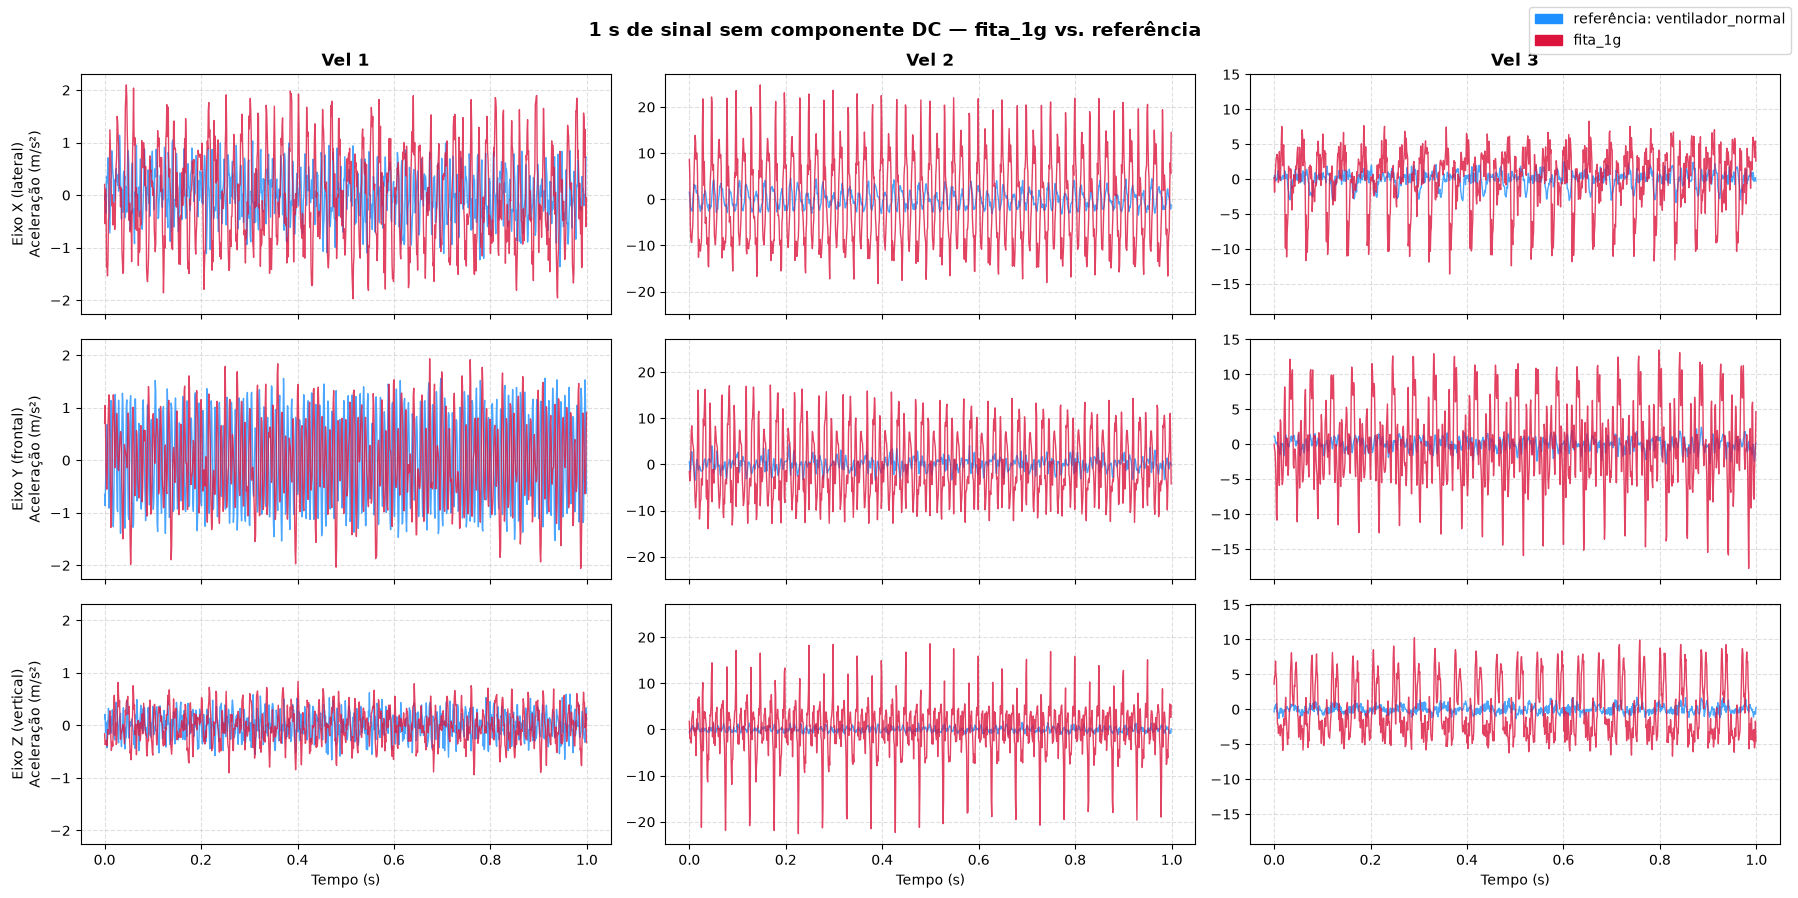

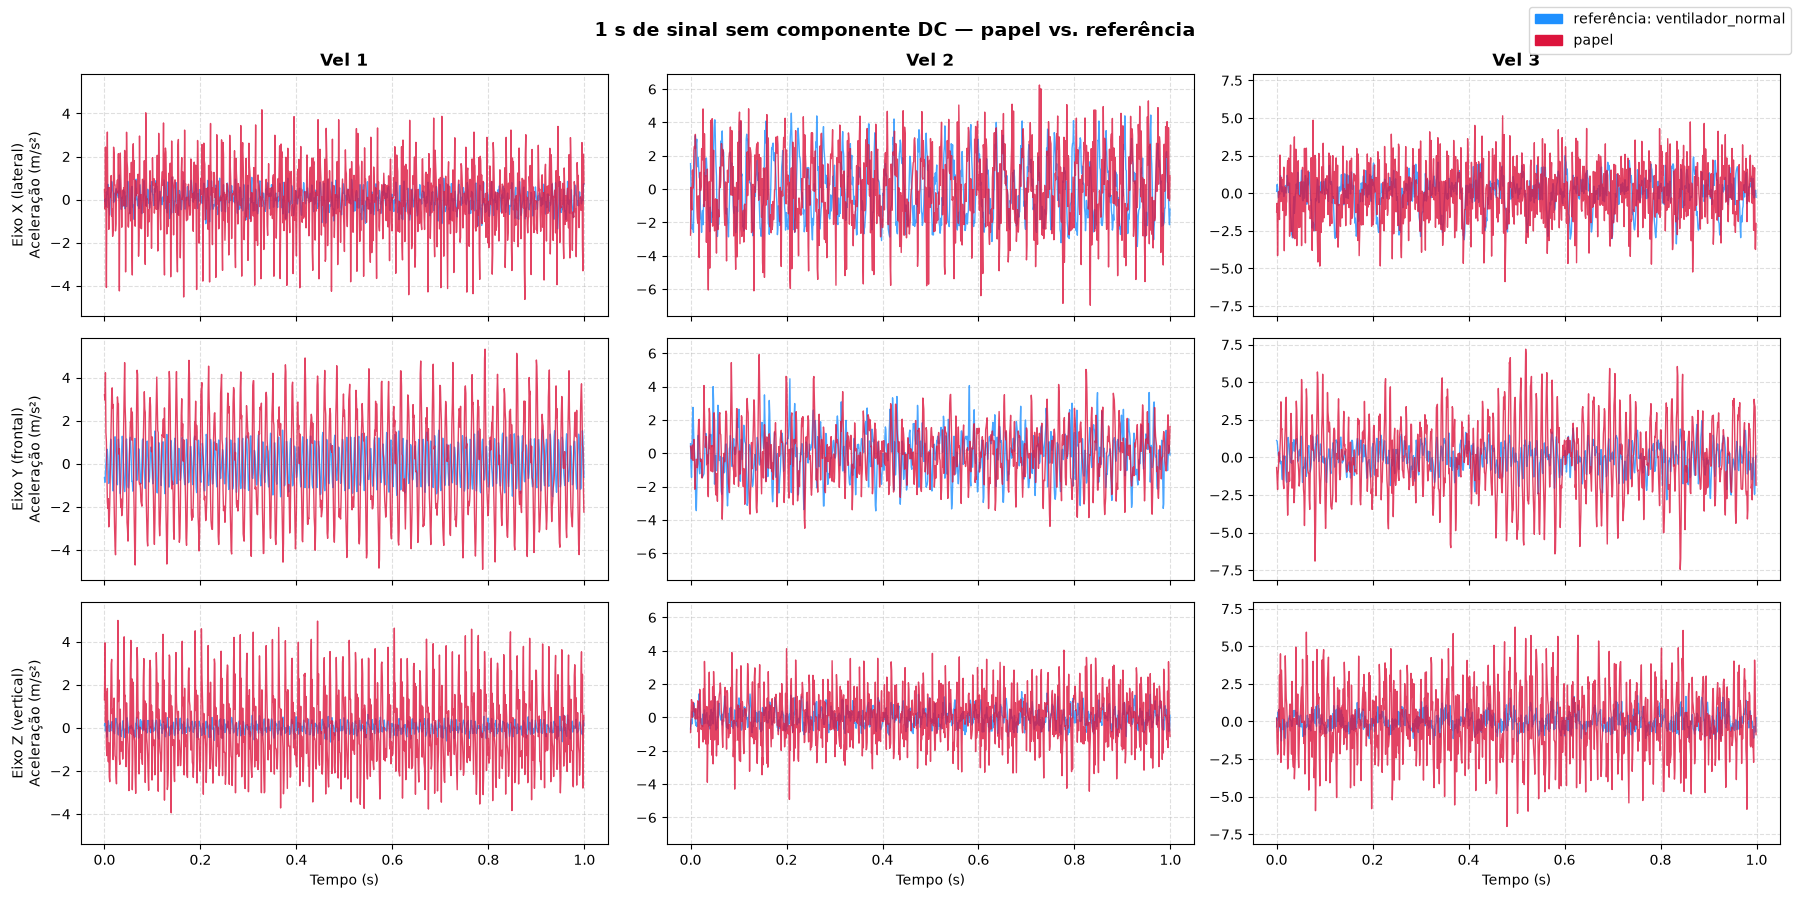

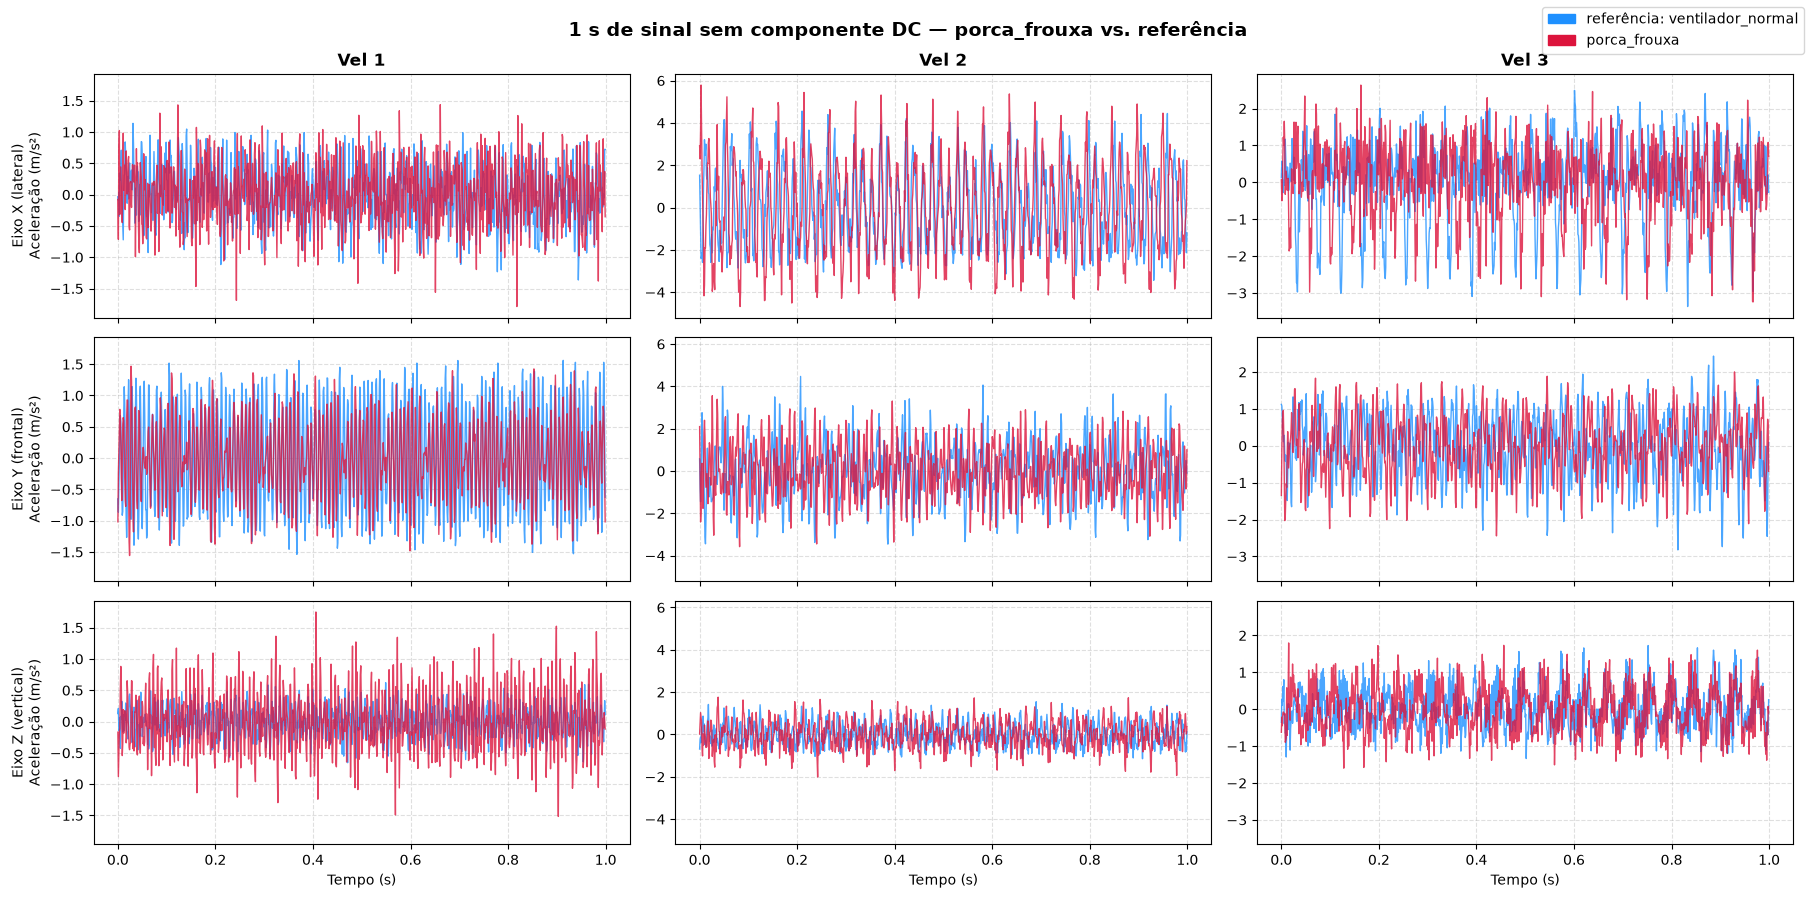

In [9]:
for condicao in condicoes_comparadas:
    plotar_sinal_comparado(bases, catalogo, CONDICOES_REFERENCIA, condicao, velocidades, inicio_s=INICIO_TRECHO_S)

### O que encontramos

* **Fita 1g:** é a diferença mais visível. Na **Vel 2** o sinal da fita chega a cerca de ±20 m/s² nos três eixos, contra cerca de ±3 m/s² do normal. Na **Vel 3** chega a cerca de ±10 a ±15 m/s². Na **Vel 1** as duas curvas quase se sobrepõem: a fita mal aparece.
* **Papel:** fica entre a fita e o normal. O sinal é maior que o normal nas três velocidades, mas sem a regularidade de pancada da fita.
* **Porca frouxa:** em 1 s de sinal ela é muito parecida com o normal, como já tinha aparecido no Notebook 01.
* **Por que a fita quase some na Vel 1?** O peso da fita gera uma força centrífuga que cresce com o **quadrado** da rotação. Na Vel 1 (cerca de 12 Hz) a força é aproximadamente 3,5 vezes menor que na Vel 3 (cerca de 23 Hz) para o mesmo 1 g. Isso é física esperada, não erro de coleta.

## Passo 5 — Features de tempo: desvio padrão, curtose e pico

**O que buscamos:** descobrir **quais features de tempo mudam com a anomalia, para que lado e quanto**, em cada velocidade. Também queremos saber se essa mudança é **maior do que a variação natural da própria referência**. Se não for, ela pode ser só deriva da gravação e não efeito da falha.

**O que cada feature mede (por janela de 5 s, por eixo):**

| Feature | O que mede | Se a anomalia aumentar... |
| --- | --- | --- |
| Desvio padrão (`std`) | Intensidade geral da vibração | A máquina vibra mais |
| Pico (`pico`) | Maior valor absoluto da janela | Há batidas ou picos mais fortes |
| Curtose (`kurt`) | **Forma** da onda, não o tamanho. Em torno de 0 é uma onda "comum"; valores altos indicam picos isolados (impactos); valores negativos indicam onda mais regular, parecida com uma senoide | A onda ficou mais "pontuda" (impactos) |

Por isso a curtose pode mudar mesmo quando o desvio padrão muda pouco, e pode até **diminuir** com a anomalia. Isso indica que a forma da onda ficou mais regular, não que a vibração diminuiu.

### 5.1 — Boxplots

Em cada gráfico há uma caixa azul (referência) e uma vermelha (anomalia) por velocidade.

* A **caixa** cobre os 50% centrais das janelas, e a **linha preta** é a mediana.
* Os **traços** (bigodes) mostram o alcance normal, e os **pontinhos** são janelas atípicas.
* **Caixas separadas, sem sobreposição:** a feature distingue as condições naquela velocidade.
* **Caixas sobrepostas:** a feature não distingue, ou distingue pouco.

### 5.2 — Medianas

Os mesmos números, em tabela. Use para ler o valor real e calcular quantas vezes a anomalia é maior ou menor que a referência.

### 5.3 — Mapa de separação

Este mapa resume, em um número, o quanto cada feature distingue as duas condições.

**Cada linha** é uma das 9 features. **Cada quadrado** mostra a **separação**, de −1 a +1:

* **+1:** todas as janelas da anomalia têm valor maior que todas as da referência.
* **0:** as duas condições estão misturadas, sem diferença.
* **−1:** todas as janelas da anomalia têm valor menor que as da referência.
* **Valores intermediários** (por exemplo 0,5) indicam que a anomalia tende a ser maior, mas as distribuições se sobrepõem em parte.

**A cor** acompanha o número. **Vermelho** significa anomalia **maior** que a referência e **azul** significa anomalia **menor**. Quanto mais escura a cor, mais forte a separação.

**As colunas** estão em dois blocos, divididos pela linha preta:

* **Esquerda (Vel 1, 2, 3):** a anomalia comparada com a referência, velocidade por velocidade. É a diferença que queremos medir.
* **Direita (controle Vel 1, 2, 3):** a **referência contra ela mesma**, comparando a segunda metade de cada gravação com a primeira. Não há falha nenhuma aqui, então mostra o quanto a referência varia sozinha ao longo do tempo (deriva, aquecimento, ajuste de velocidade).

**Como interpretar:**

1. **Cor forte à esquerda e cor fraca (clara) à direita:** a feature é confiável. A diferença vem da anomalia.
2. **Cor forte nos dois blocos:** a referência já muda sozinha nessa velocidade. A diferença pode ser deriva e não falha, então desconfie dessa feature naquela velocidade.
3. **Cor clara à esquerda:** a feature não distingue as condições. Isso também é informação útil.
4. **Sinais opostos entre velocidades** (vermelho numa e azul em outra): a anomalia muda a feature de forma diferente conforme a rotação.

**Cuidado:** janelas vizinhas são parecidas entre si (autocorrelação), então a separação é um **guia visual**, não um teste estatístico. O teste vem no Notebook 03.

In [10]:
def plotar_boxplots_comparativo(features, condicoes_ref, condicao, linhas, velocidades):
    """Grade (linhas = tipos de feature, colunas = eixos), com duas caixas por velocidade.

    linhas: lista de (prefixo, título, unidade), por exemplo ("std", "Desvio padrão", "m/s²").
    """
    fig, axs = plt.subplots(len(linhas), len(EIXOS), figsize=(18, 3.6 * len(linhas)), squeeze=False)
    for i, (prefixo, titulo, unidade) in enumerate(linhas):
        for j, eixo in enumerate(EIXOS):
            ax = axs[i, j]
            for k, velocidade in enumerate(velocidades):
                grupos = ((-0.2, condicoes_ref, COR_REFERENCIA), (0.2, [condicao], COR_COMPARADA))
                for deslocamento, condicoes, cor in grupos:
                    valores = selecionar_janelas(features, condicoes, velocidade)[f"{prefixo}_{eixo}"]
                    if len(valores) == 0:
                        continue
                    caixa = ax.boxplot(
                        valores, positions=[k + deslocamento], widths=0.35, patch_artist=True,
                        manage_ticks=False, flierprops={"markersize": 3, "alpha": 0.5},
                    )
                    for parte in caixa["boxes"]:
                        parte.set_facecolor(cor)
                        parte.set_alpha(0.7)
                    for mediana in caixa["medians"]:
                        mediana.set_color("black")
            ax.set_xticks(range(len(velocidades)))
            ax.set_xticklabels([f"Vel {v}" for v in velocidades])
            ax.set_title(f"{titulo} — {NOMES_EIXOS[eixo]}", fontsize=11, fontweight="bold")
            ax.set_ylabel(unidade)
    fig.legend(
        handles=[Patch(color=COR_REFERENCIA, label="referência"), Patch(color=COR_COMPARADA, label=condicao)],
        loc="upper right", fontsize=10,
    )
    fig.suptitle(f"{condicao} vs. referência", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def montar_tabela_de_medianas(features, condicoes_ref, condicao, colunas, velocidades):
    """Mediana de cada feature, por velocidade, na referência e na anomalia."""
    tabela = {}
    for velocidade in velocidades:
        ref = selecionar_janelas(features, condicoes_ref, velocidade)[colunas].median()
        comp = selecionar_janelas(features, [condicao], velocidade)[colunas].median()
        tabela[(f"Vel {velocidade}", "referência")] = ref
        tabela[(f"Vel {velocidade}", "anomalia")] = comp
    return pd.DataFrame(tabela)


def montar_matriz_de_separacao(features, condicoes_ref, condicao, colunas, velocidades):
    """Matriz (feature x [comparação das velocidades | controle das velocidades]) com a separação."""
    colunas_matriz = {}
    for velocidade in velocidades:
        ref = selecionar_janelas(features, condicoes_ref, velocidade)
        comp = selecionar_janelas(features, [condicao], velocidade)
        colunas_matriz[f"Vel {velocidade}"] = calcular_separacao(comp, ref, colunas)
    for velocidade in velocidades:
        ref = selecionar_janelas(features, condicoes_ref, velocidade)
        colunas_matriz[f"controle Vel {velocidade}"] = calcular_separacao_controle(ref, colunas)
    return pd.DataFrame(colunas_matriz)


def plotar_mapa_de_separacao(matriz, titulo, n_colunas_comparacao):
    """Mapa de cores (vermelho = anomalia maior, azul = menor) com o valor escrito em cada célula."""
    fig, ax = plt.subplots(figsize=(1.6 * matriz.shape[1] + 3, 0.45 * matriz.shape[0] + 2))
    imagem = ax.imshow(matriz.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(matriz.shape[1]))
    ax.set_xticklabels(matriz.columns, rotation=30, ha="right")
    ax.set_yticks(range(matriz.shape[0]))
    ax.set_yticklabels(matriz.index)
    ax.grid(False)
    ax.axvline(n_colunas_comparacao - 0.5, color="black", linewidth=2)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            valor = matriz.iloc[i, j]
            if not np.isnan(valor):
                ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if abs(valor) > 0.6 else "black")
    fig.colorbar(imagem, ax=ax, label="separação (+ anomalia maior, − anomalia menor)")
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 5.1 a 5.3 — Para cada condição comparada

==================== fita_1g vs. referência ====================


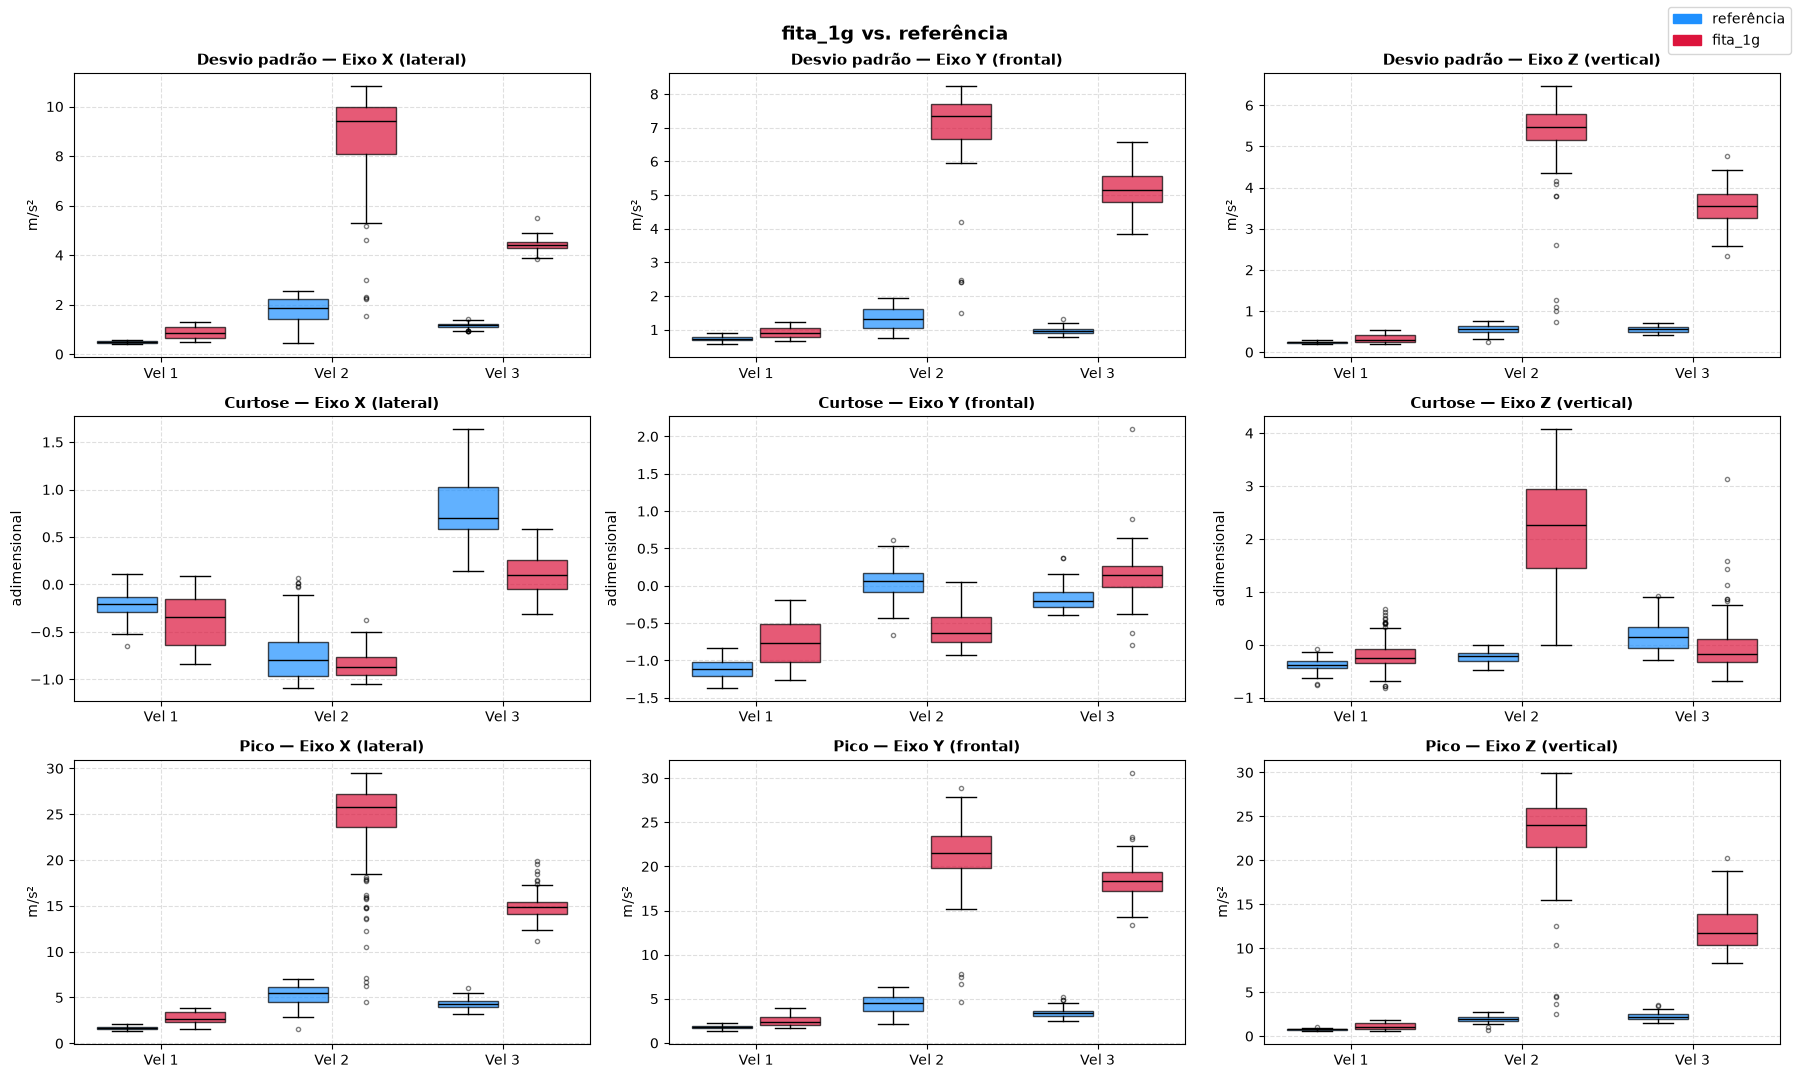

Medianas de cada feature de tempo:


Vel 1               Vel 2               Vel 3         
       referência anomalia referência anomalia referência anomalia
std_x       0.486    0.838      1.882    9.400      1.159    4.419
std_y       0.732    0.914      1.316    7.335      0.957    5.154
std_z       0.239    0.295      0.564    5.483      0.569    3.559
kurt_x     -0.208   -0.346     -0.799   -0.875      0.697    0.095
kurt_y     -1.118   -0.769      0.070   -0.635     -0.204    0.139
kurt_z     -0.387   -0.255     -0.219    2.256      0.147   -0.170
pico_x      1.648    2.644      5.497   25.791      4.316   14.855
pico_y      1.772    2.387      4.556   21.504      3.335   18.347
pico_z      0.779    0.988      1.974   23.990      2.194   11.754

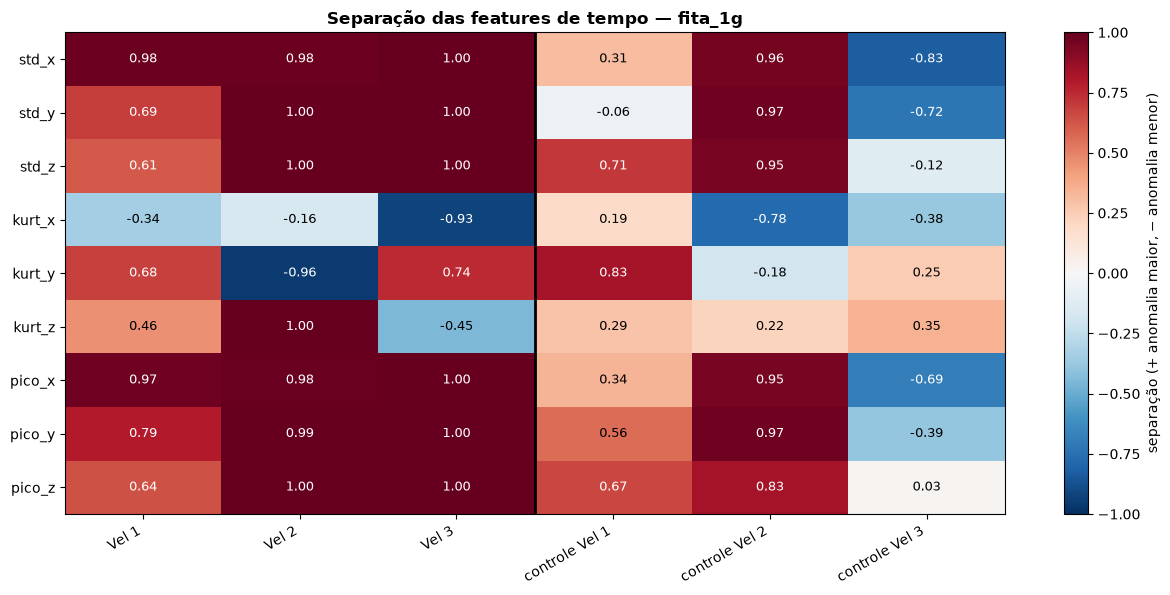

==================== papel vs. referência ====================


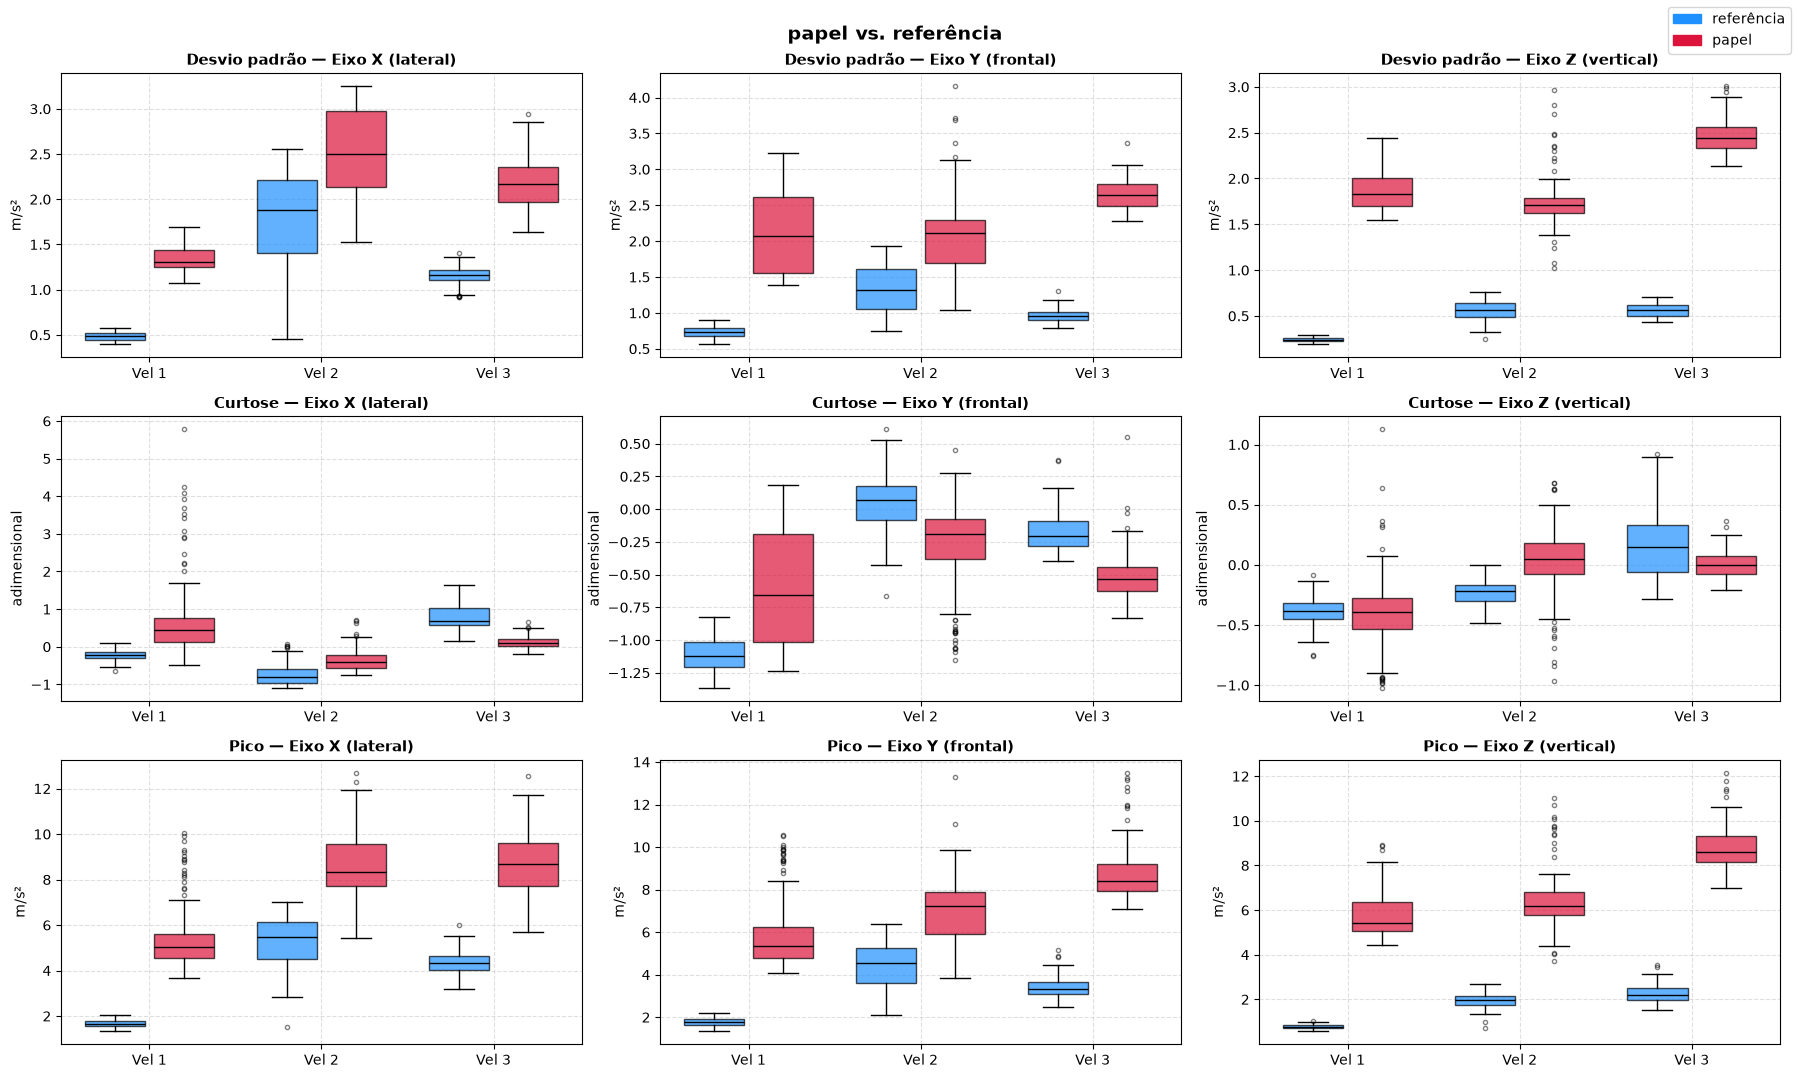

Medianas de cada feature de tempo:


Vel 1               Vel 2               Vel 3         
       referência anomalia referência anomalia referência anomalia
std_x       0.486    1.308      1.882    2.502      1.159    2.166
std_y       0.732    2.066      1.316    2.106      0.957    2.641
std_z       0.239    1.826      0.564    1.708      0.569    2.447
kurt_x     -0.208    0.449     -0.799   -0.409      0.697    0.108
kurt_y     -1.118   -0.658      0.070   -0.190     -0.204   -0.533
kurt_z     -0.387   -0.394     -0.219    0.049      0.147    0.001
pico_x      1.648    5.051      5.497    8.352      4.316    8.705
pico_y      1.772    5.367      4.556    7.211      3.335    8.426
pico_z      0.779    5.436      1.974    6.186      2.194    8.603

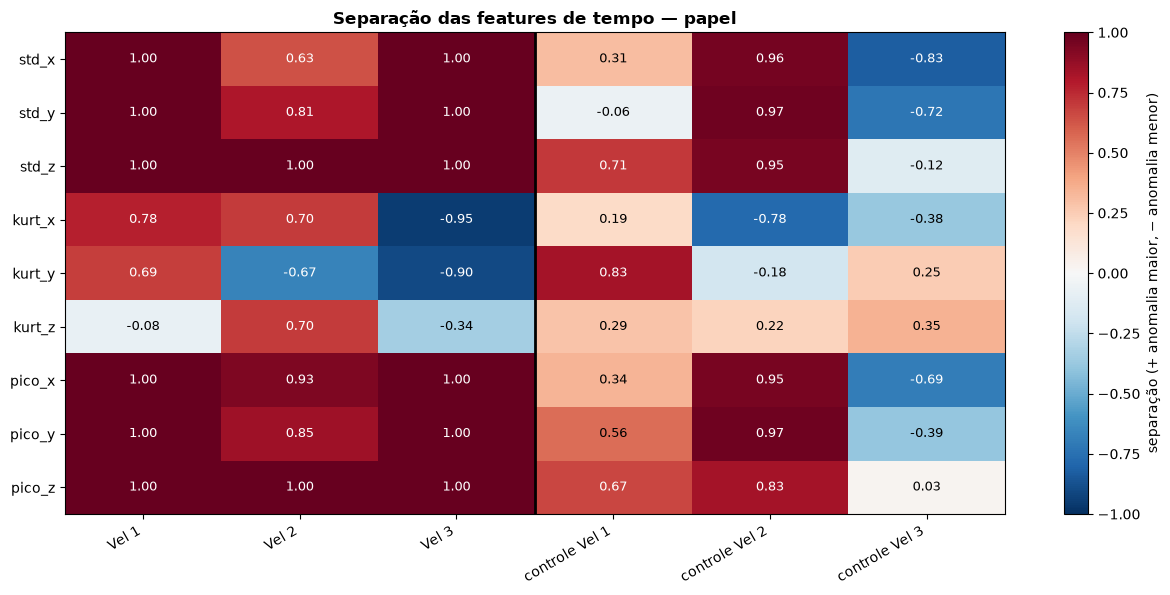

==================== porca_frouxa vs. referência ====================


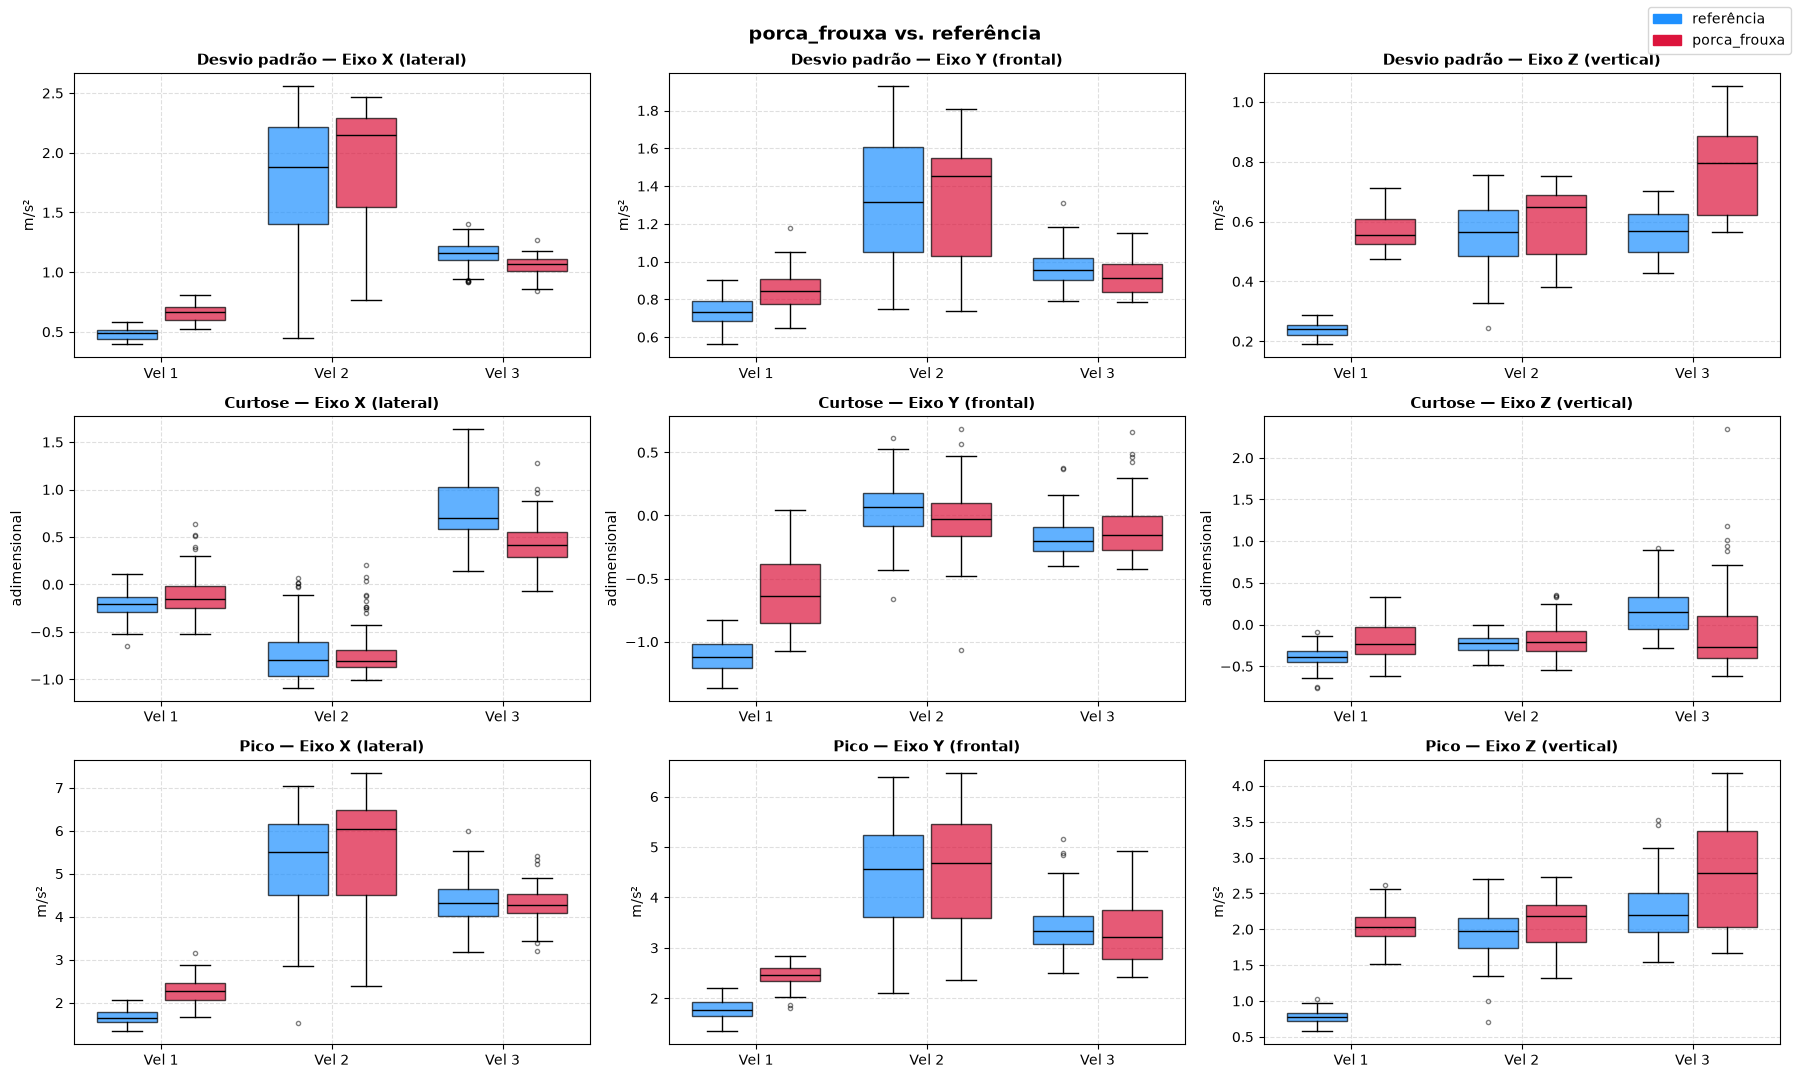

Medianas de cada feature de tempo:


Vel 1               Vel 2               Vel 3         
       referência anomalia referência anomalia referência anomalia
std_x       0.486    0.664      1.882    2.150      1.159    1.065
std_y       0.732    0.845      1.316    1.453      0.957    0.913
std_z       0.239    0.556      0.564    0.649      0.569    0.794
kurt_x     -0.208   -0.156     -0.799   -0.811      0.697    0.420
kurt_y     -1.118   -0.636      0.070   -0.029     -0.204   -0.154
kurt_z     -0.387   -0.236     -0.219   -0.203      0.147   -0.271
pico_x      1.648    2.276      5.497    6.031      4.316    4.280
pico_y      1.772    2.467      4.556    4.676      3.335    3.221
pico_z      0.779    2.036      1.974    2.179      2.194    2.783

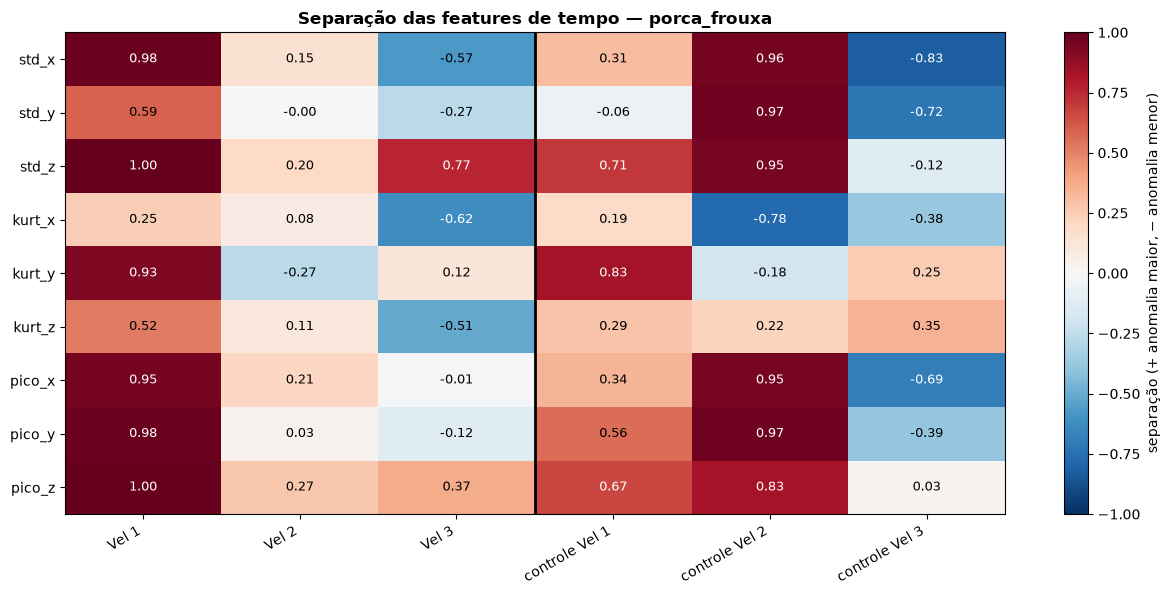

In [11]:
LINHAS_TEMPO = [("std", "Desvio padrão", UNIDADE), ("kurt", "Curtose", "adimensional"), ("pico", "Pico", UNIDADE)]

for condicao in condicoes_comparadas:
    print(f"==================== {condicao} vs. referência ====================")
    plotar_boxplots_comparativo(features, CONDICOES_REFERENCIA, condicao, LINHAS_TEMPO, velocidades)

    print("Medianas de cada feature de tempo:")
    display(montar_tabela_de_medianas(features, CONDICOES_REFERENCIA, condicao, COLUNAS_TEMPO, velocidades).round(3))

    matriz = montar_matriz_de_separacao(features, CONDICOES_REFERENCIA, condicao, COLUNAS_TEMPO, velocidades)
    plotar_mapa_de_separacao(matriz, f"Separação das features de tempo — {condicao}", len(velocidades))

### O que encontramos (medianas e matriz de separação das features de tempo)

**Fita 1g**
* **Vel 2 e Vel 3:** separação perfeita. Na Vel 2, `std_x` sobe de 1,88 para 9,40 e `pico_z` de 1,97 para 23,99, cerca de 12 vezes. Na Vel 3, `std_y` sobe de 0,96 para 5,15.
* **Vel 1:** os aumentos são pequenos (`std_x` de 0,49 para 0,84) e **não superam o controle**. O controle da Vel 1 já é alto por causa do aquecimento.

**Papel**
* Sobe `std` e `pico` nos três eixos **em todas as velocidades**. O maior efeito relativo é no eixo Z na Vel 1: `std_z` vai de 0,24 para 1,83, mais de 7 vezes.
* Diferente da fita, o efeito do papel **não cresce tanto com a velocidade**: na Vel 2, `std_x` vai só de 1,88 para 2,50.

**Porca frouxa**
* **Vel 1:** `std_z` sobe de 0,24 para 0,56 e `pico_z` de 0,78 para 2,04, com separação de 1,00.
* **Vel 2:** nenhuma feature de tempo passa de 0,27.
* **Vel 3:** sinais misturados. `std_x`, `kurt_x` e `kurt_z` ficam **menores** que no normal, e `std_z` fica maior.
* Ou seja, **no tempo a porca só aparece de forma clara na Vel 1**.

**Curtose:** é a feature menos útil aqui. Ela só separa bem na fita Vel 2 (`kurt_z` de −0,22 para 2,26), onde o sinal vira uma sequência de pancadas.

## Passo 6 — Espectro médio: referência sobre anomalia

**O que buscamos:** ver **em quais frequências** a anomalia aparece. Em vez de uma única janela (como no Notebook 01), usamos **todas as janelas** de cada condição: a linha é a **média** do espectro e a faixa sombreada vai do percentil 10 ao 90. Assim vemos o espectro típico e também o quanto ele varia.

Como ler: picos vermelhos que **não existem** no azul são frequências novas da anomalia. Picos nas mesmas frequências, mas mais altos, indicam a mesma vibração, só que mais forte. Se duas faixas sombreadas não se tocam, a diferença é consistente em todas as janelas. Cada coluna (velocidade) compartilha a escala vertical entre os três eixos.

In [12]:
def resumir_espectros(espectros):
    """Média e percentis 10 e 90 de um conjunto de espectros (janela, frequência, eixo)."""
    return espectros.mean(axis=0), np.percentile(espectros, 10, axis=0), np.percentile(espectros, 90, axis=0)


def plotar_espectros_comparados(features, frequencias, espectros_por_base, condicoes_ref, condicao, velocidades):
    """Grade (eixo x velocidade): espectro médio e faixa de percentis 10 a 90, referência e anomalia."""
    fig, axs = plt.subplots(
        len(EIXOS), len(velocidades), figsize=(7 * len(velocidades), 3.2 * len(EIXOS)),
        sharex=True, sharey="col", squeeze=False,
    )
    visivel = frequencias <= F_MAX_PLOT_HZ
    for j, velocidade in enumerate(velocidades):
        for cor, condicoes in ((COR_REFERENCIA, condicoes_ref), (COR_COMPARADA, [condicao])):
            janelas = selecionar_janelas(features, condicoes, velocidade)
            if len(janelas) == 0:
                continue
            media, p10, p90 = resumir_espectros(juntar_espectros(espectros_por_base, janelas))
            for i in range(len(EIXOS)):
                axs[i, j].fill_between(frequencias[visivel], p10[visivel, i], p90[visivel, i], color=cor, alpha=0.25)
                axs[i, j].plot(frequencias[visivel], media[visivel, i], color=cor, linewidth=1.1)
        axs[0, j].set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        axs[-1, j].set_xlabel("Frequência (Hz)")
    for i, eixo in enumerate(EIXOS):
        axs[i, 0].set_ylabel(f"{NOMES_EIXOS[eixo]}\nMagnitude ({UNIDADE})")
    if ESCALA_Y_FFT == "log":
        for ax in axs.ravel():
            ax.set_yscale("log")
    fig.legend(
        handles=[Patch(color=COR_REFERENCIA, label="referência: " + ", ".join(condicoes_ref)),
                 Patch(color=COR_COMPARADA, label=condicao)],
        loc="upper right", fontsize=10,
    )
    fig.suptitle(f"Espectro médio com Hanning (faixa = percentis 10 a 90) — {condicao} vs. referência",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

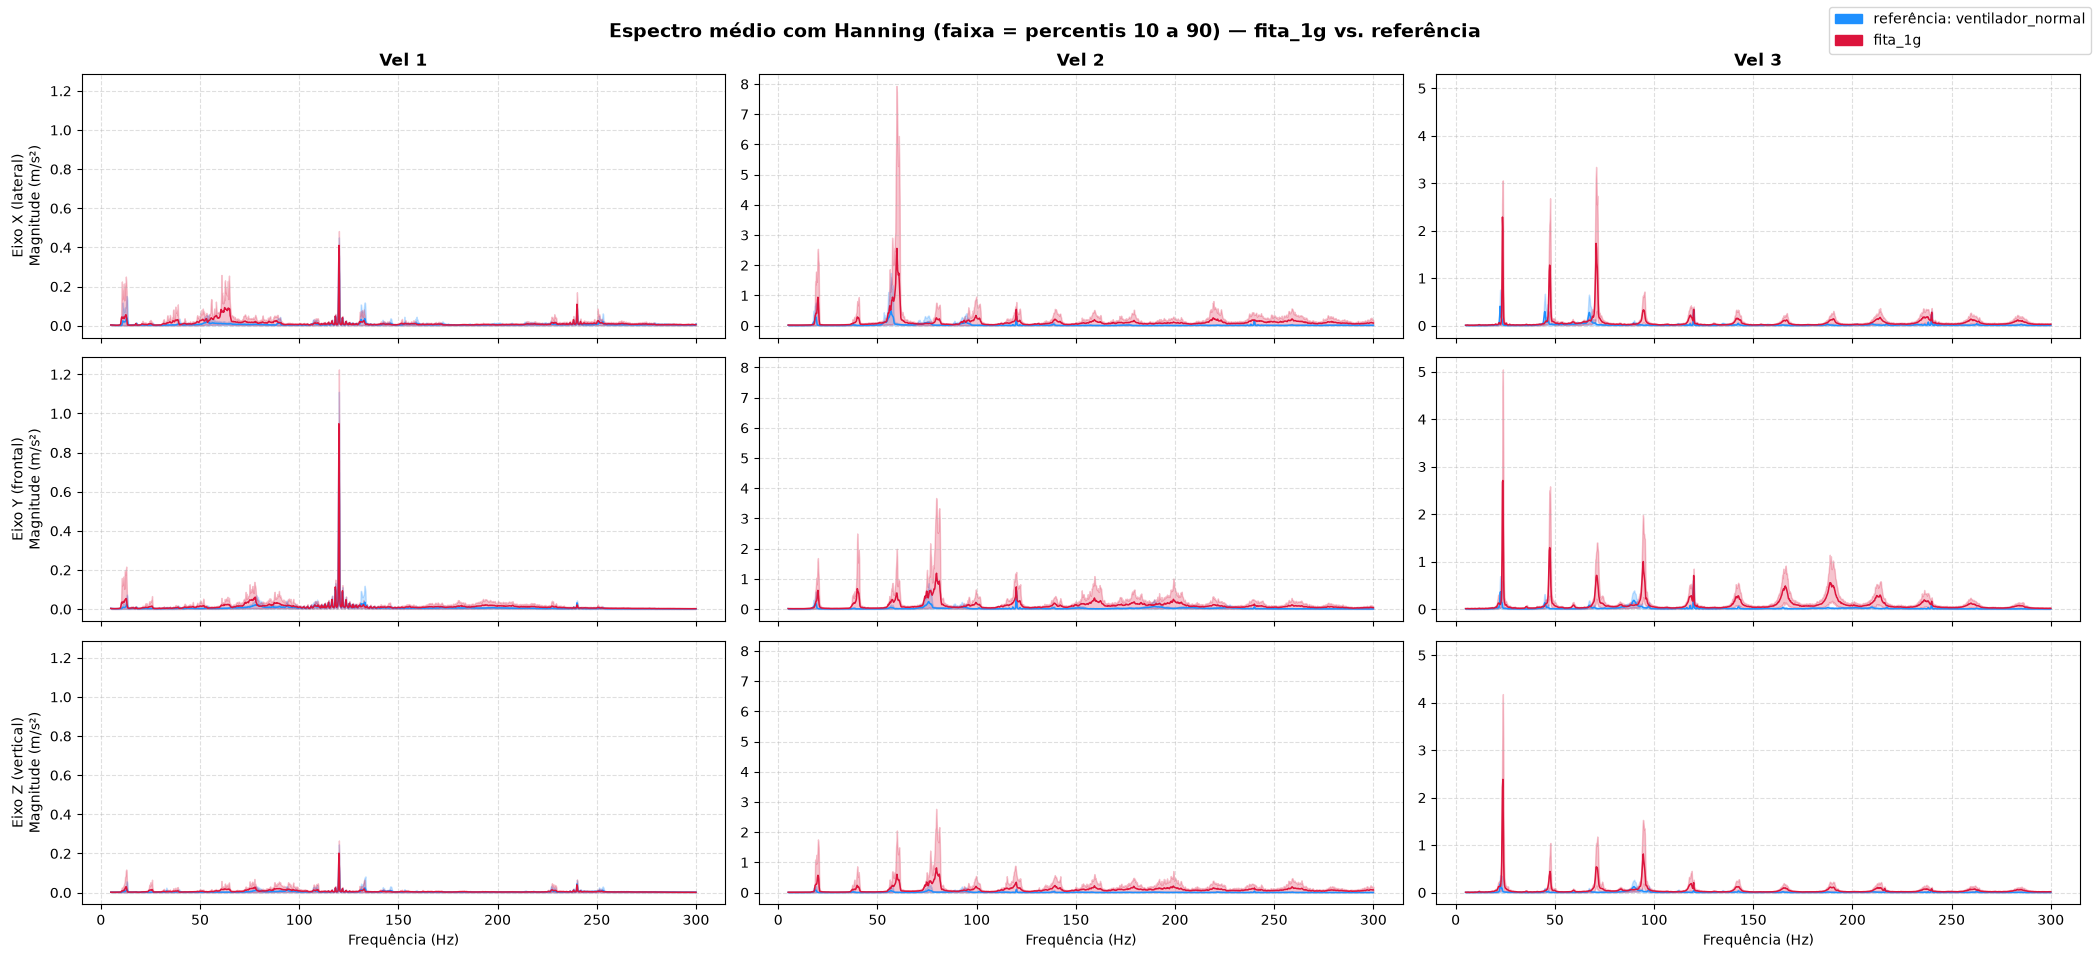

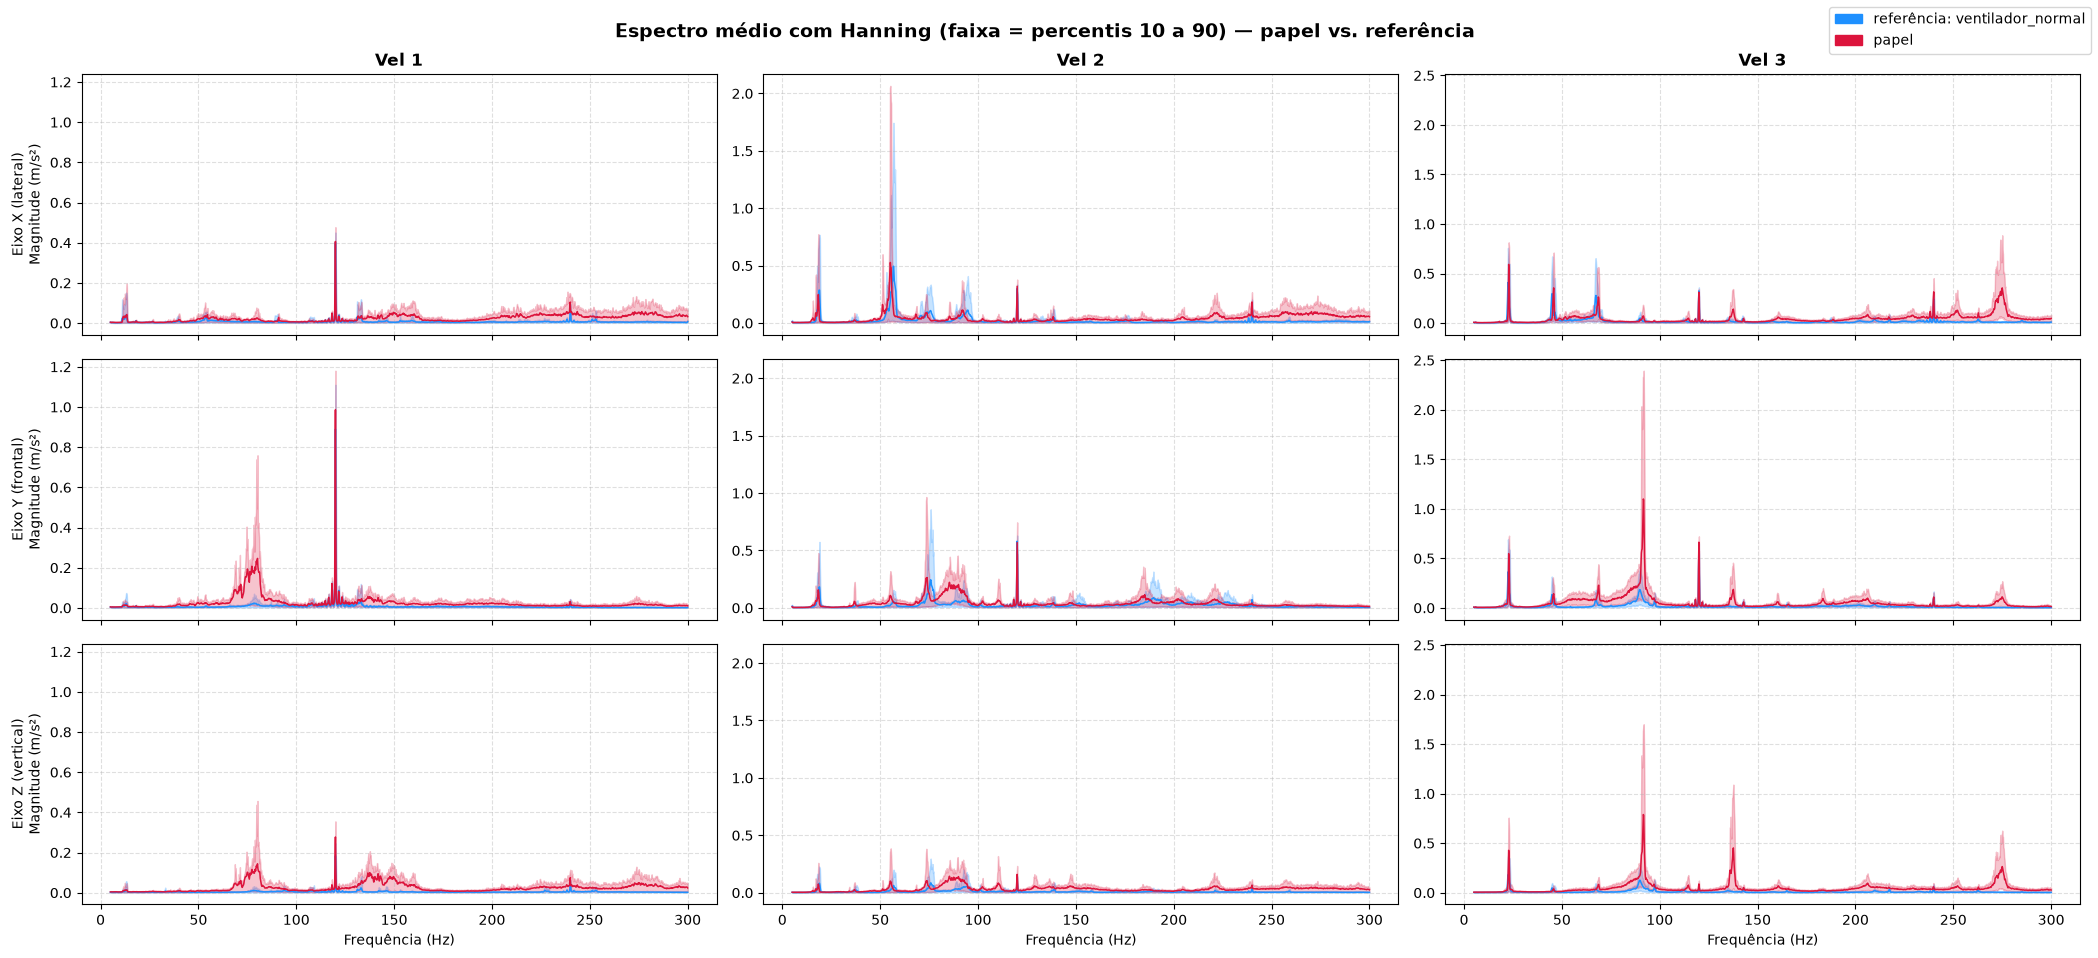

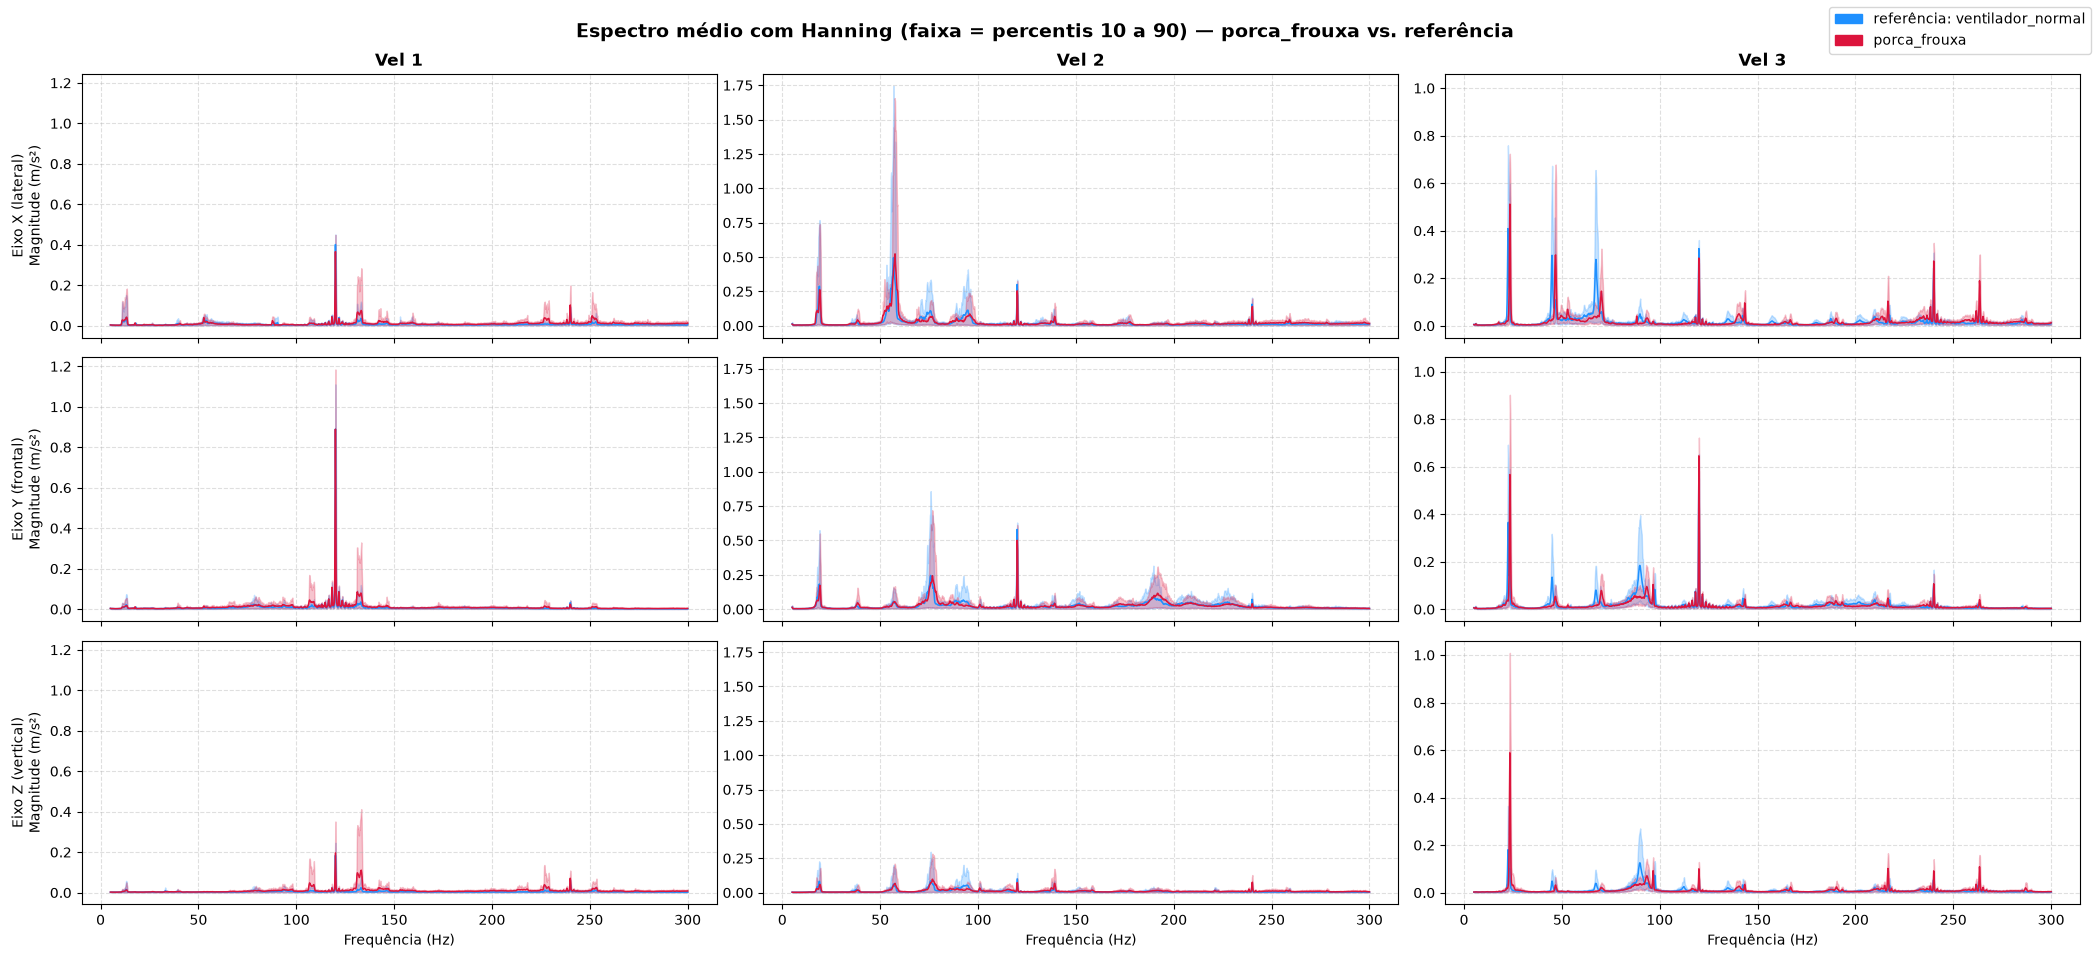

In [13]:
for condicao in condicoes_comparadas:
    plotar_espectros_comparados(features, frequencias, espectros_por_base, CONDICOES_REFERENCIA, condicao, velocidades)

### O que encontramos (espectros médios)

* **Linhas fixas em 120 e 240 Hz:** aparecem **em todas as condições, inclusive no normal**, e na mesma posição nas três velocidades (Notebook 01). Uma frequência de máquina mudaria com a velocidade; essas não mudam. Então elas não indicam falha. Origem provável: elétrica (a confirmar com o orientador).
* **Fita 1g:** o espectro inteiro sobe, principalmente na **1X** (rotação) e nas harmônicas. A amplitude da 1X fica 1,8 a 10 vezes maior que no normal, conforme o eixo e a velocidade. Esse é o sinal clássico de **desbalanceamento**: massa extra fora do centro gira junto com a hélice e empurra o eixo uma vez por volta.
* **Papel:** a 1X fica **parecida com a do normal** (Vel 3, eixo X: 0,70 contra 0,68). O que muda são picos e regiões **fora das harmônicas da rotação**: cerca de 70–80 Hz nos eixos Y e Z na Vel 1, cerca de 90 Hz e cerca de 140 Hz na Vel 3, e um aumento largo acima de 250 Hz. É o comportamento esperado de algo **raspando ou batendo** (atrito, turbulência), não de massa a mais.
* **Porca frouxa:** a 1X também fica igual à do normal. As diferenças são pequenas e espalhadas: picos novos perto de 105–135 Hz na Vel 1 e em 215–265 Hz na Vel 3. Na Vel 2 os espectros praticamente se sobrepõem.
* **Pico grande perto de 57 Hz no eixo X na Vel 2**, em todas as condições: fica perto da **3X** dessa velocidade (3 × cerca de 19 Hz). A `amp_3x_x` da fita na Vel 2 chega a 7,95, contra 1,57 do normal. Hipótese **a confirmar**: uma ressonância da estrutura perto dessa frequência, que amplifica a falha justamente na Vel 2. Isso explicaria por que a fita fica mais forte na Vel 2 do que na Vel 3.

## Passo 7 — Mapa por faixa de 10 Hz: onde o espectro muda

**O que buscamos:** descobrir **em quais frequências, em quais eixos e em quanto** a anomalia muda a vibração em relação à referência. No Passo 6 vimos o espectro inteiro; aqui o resumimos em um mapa fácil de ler, que também mostra onde olhar com mais atenção nos próximos passos.

### Como o mapa é construído

1. O espectro de cada janela é dividido em **faixas de 10 Hz** (5–15 Hz, 15–25 Hz, e assim até 305 Hz). Em cada faixa guardamos o **maior valor** que o espectro atinge. São as 90 features de FFT do dataset (30 faixas × 3 eixos).
2. Para cada faixa e eixo, calculamos o valor típico (**mediana** das janelas) da referência e da anomalia.
3. Dividimos um pelo outro e obtemos **quantas vezes a anomalia vibra mais ou menos** que a referência naquela faixa.

### Como ler o gráfico

Há um mapa por velocidade. Cada **quadradinho** é uma faixa de 10 Hz (horizontal) em um eixo (vertical).

| Cor | Significado |
| --- | --- |
| **Vermelho** | A anomalia vibra **mais** que a referência nessa faixa. Quanto mais escuro, mais vezes maior (a legenda mostra "2× maior", "5× maior", "10× maior"). |
| **Branco** | A anomalia vibra **igual** à referência. |
| **Azul** | A anomalia vibra **menos** que a referência nessa faixa. |
| **Cinza** | A diferença **não é consistente** entre as janelas. Não dá para afirmar que a faixa mudou. |

### Por que algumas faixas ficam cinza

A mediana pode mudar bastante e, mesmo assim, as janelas das duas condições se misturarem. Isso acontece quando a faixa oscila muito de uma janela para outra. Nesse caso a mudança não é confiável, e pintar de vermelho enganaria.

Para decidir, usamos a **separação** do Passo 5, que vai de −1 a +1 e mede se as janelas da anomalia ficam todas acima (ou todas abaixo) das da referência. Faixas com separação (em valor absoluto) abaixo de `LIMIAR_SEPARACAO` ficam cinza. O valor padrão é 0,5, e você pode aumentá-lo para ser mais rigoroso ou diminuí-lo para ser mais tolerante.

### O que procurar no mapa

* **Faixas vermelhas escuras e consistentes:** onde a anomalia mais aparece. São boas candidatas a features para o modelo.
* **Muito cinza em uma velocidade:** nessa velocidade a anomalia é mais difícil de distinguir pela frequência. Confira o Passo 9.
* **Faixas azuis:** a anomalia **reduz** a vibração nessa frequência. É raro e vale investigar.
* **Faixas em 120 Hz e 240 Hz:** costumam ser a rede elétrica e tendem a ficar iguais nas duas condições. Não são da falha.
* **Todo o mapa vermelho:** a anomalia aumenta a vibração geral, não só em uma frequência específica. É o caso de falhas fortes, em que o espectro inteiro sobe.

### Cuidados

* O mapa mostra **onde** e **quanto** o espectro muda, mas **não explica o porquê**. Para ligar a mudança a uma causa (como desbalanceamento), veja o Passo 8, com 1X, 2X e 3X.
* Janelas vizinhas são parecidas entre si (autocorrelação), então a separação é um guia visual e **não** um teste estatístico. O teste vem no Notebook 03.

In [14]:
def calcular_mapas_por_faixa(features, condicoes_ref, condicao, velocidade):
    """Mapas (eixo x faixa) de mudança em dB e de separação, para uma velocidade.

    Devolve (mudanca_db, separacao), cada um com formato (3 eixos, número de faixas).
    """
    ref = selecionar_janelas(features, condicoes_ref, velocidade)
    comp = selecionar_janelas(features, [condicao], velocidade)
    n_faixas = len(faixas_de_frequencia())
    if len(ref) == 0 or len(comp) == 0:
        vazio = np.full((len(EIXOS), n_faixas), np.nan)
        return vazio, vazio
    mudanca_db, separacao = [], []
    for eixo in EIXOS:
        colunas = colunas_fft_do_eixo(eixo)
        mediana_ref = ref[colunas].median().to_numpy()
        mediana_comp = comp[colunas].median().to_numpy()
        mudanca_db.append(20 * np.log10((mediana_comp + EPS) / (mediana_ref + EPS)))
        separacao.append(calcular_separacao(comp, ref, colunas).to_numpy())
    return np.array(mudanca_db), np.array(separacao)


def plotar_mapas_por_faixa(features, condicoes_ref, condicao, velocidades):
    """Grade 2 x velocidades: em cima a mudança em dB, embaixo a separação, por eixo e faixa de 10 Hz."""
    mapas = {v: calcular_mapas_por_faixa(features, condicoes_ref, condicao, v) for v in velocidades}
    todos_db = np.concatenate([m[0].ravel() for m in mapas.values()])
    limite_db = np.nanpercentile(np.abs(todos_db), 98)
    extensao = [FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1], len(EIXOS) - 0.5, -0.5]

    fig, axs = plt.subplots(2, len(velocidades), figsize=(7 * len(velocidades), 6), sharex=True, squeeze=False)
    for j, velocidade in enumerate(velocidades):
        mudanca_db, separacao = mapas[velocidade]
        imagem_db = axs[0, j].imshow(mudanca_db, cmap="RdBu_r", vmin=-limite_db, vmax=limite_db,
                                     aspect="auto", extent=extensao, interpolation="nearest")
        imagem_sep = axs[1, j].imshow(separacao, cmap="RdBu_r", vmin=-1, vmax=1,
                                      aspect="auto", extent=extensao, interpolation="nearest")
        axs[0, j].set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        axs[1, j].set_xlabel("Frequência (Hz)")
        for i in range(2):
            axs[i, j].set_yticks(range(len(EIXOS)))
            axs[i, j].set_yticklabels([f"Eixo {e.upper()}" for e in EIXOS])
            axs[i, j].grid(False)
    axs[0, 0].set_ylabel("mudança (dB)")
    axs[1, 0].set_ylabel("separação")
    fig.colorbar(imagem_db, ax=axs[0, :], shrink=0.9, label="mudança em dB (+ anomalia maior)")
    fig.colorbar(imagem_sep, ax=axs[1, :], shrink=0.9, label="separação (+ anomalia maior)")
    fig.suptitle(f"Mapa por faixa de {LARGURA_FAIXA_HZ} Hz — {condicao} vs. referência", fontsize=14, fontweight="bold")
    plt.show()

In [15]:
LIMIAR_SEPARACAO = 0.5   # faixas com separação (em valor absoluto) abaixo disto ficam cinza


def plotar_mapa_simples(features, condicoes_ref, condicao, velocidades, limiar=LIMIAR_SEPARACAO):
    """Um mapa por velocidade: cor = quantas vezes a anomalia é maior (vermelho) ou menor (azul) que a referência.
    Faixas em que a diferença não é consistente (separação abaixo do limiar) ficam cinza."""
    mapas = {v: calcular_mapas_por_faixa(features, condicoes_ref, condicao, v) for v in velocidades}
    razoes = {v: 10 ** (m[0] / 20) for v, m in mapas.items()}                 # dB -> "quantas vezes"
    limite = np.nanpercentile(np.abs(np.log10(np.concatenate([r.ravel() for r in razoes.values()]))), 98)
    extensao = [FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1], len(EIXOS) - 0.5, -0.5]
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("lightgrey")

    fig, axs = plt.subplots(1, len(velocidades), figsize=(7 * len(velocidades), 3.2), sharex=True, squeeze=False)
    for ax, velocidade in zip(axs[0], velocidades):
        separacao = mapas[velocidade][1]
        valores = np.log10(razoes[velocidade])
        valores = np.where(np.abs(separacao) >= limiar, valores, np.nan)       # cinza = não consistente
        imagem = ax.imshow(np.ma.masked_invalid(valores), cmap=cmap, vmin=-limite, vmax=limite,
                           aspect="auto", extent=extensao, interpolation="nearest")
        ax.set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Frequência (Hz)")
        ax.set_yticks(range(len(EIXOS)))
        ax.set_yticklabels([f"Eixo {e.upper()}" for e in EIXOS])
        ax.grid(False)
    vezes = [v for v in (0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100) if abs(np.log10(v)) <= limite]
    barra = fig.colorbar(imagem, ax=axs[0, :], shrink=0.9, label="anomalia comparada com a referência")
    barra.set_ticks(np.log10(vezes))
    barra.set_ticklabels([f"{v:g}× maior" if v > 1 else ("igual" if v == 1 else f"{1/v:g}× menor") for v in vezes])
    fig.suptitle(f"{condicao} vs. referência: quantas vezes a vibração mudou em cada faixa de {LARGURA_FAIXA_HZ} Hz",
                 fontsize=13, fontweight="bold", y=1.12)
    fig.text(0.5, -0.12, "Cinza = faixa em que a diferença não é consistente entre as janelas (não dá para afirmar que mudou)",
             ha="center", fontsize=10, color="dimgray")
    plt.show()

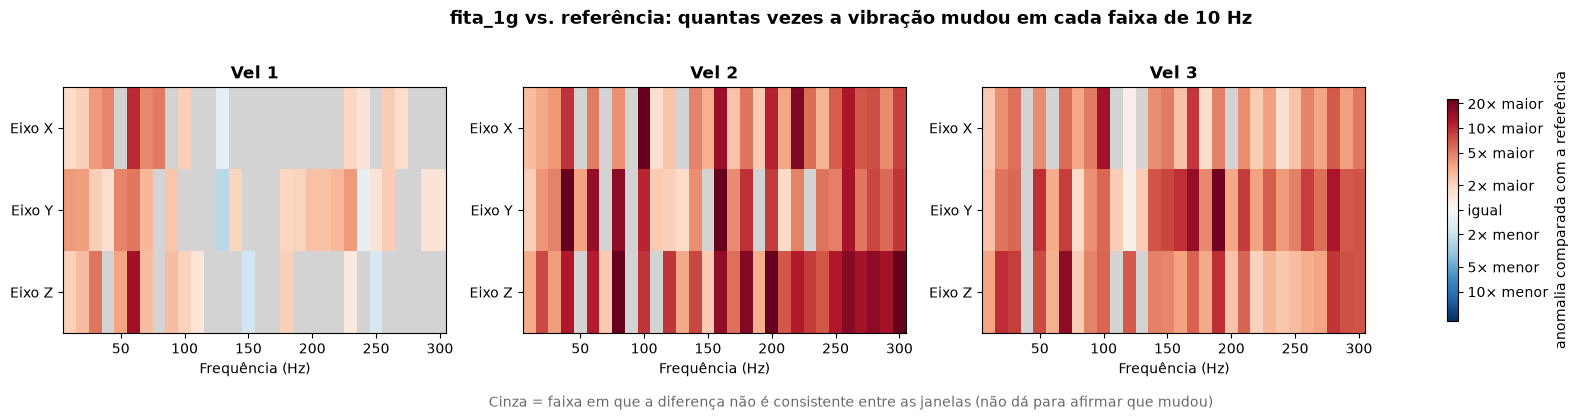

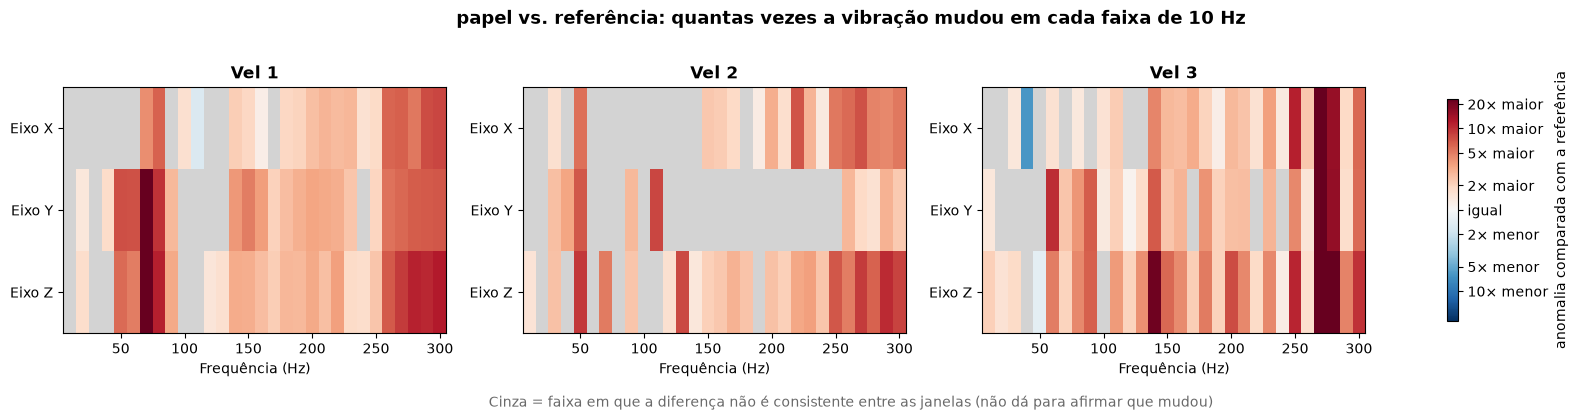

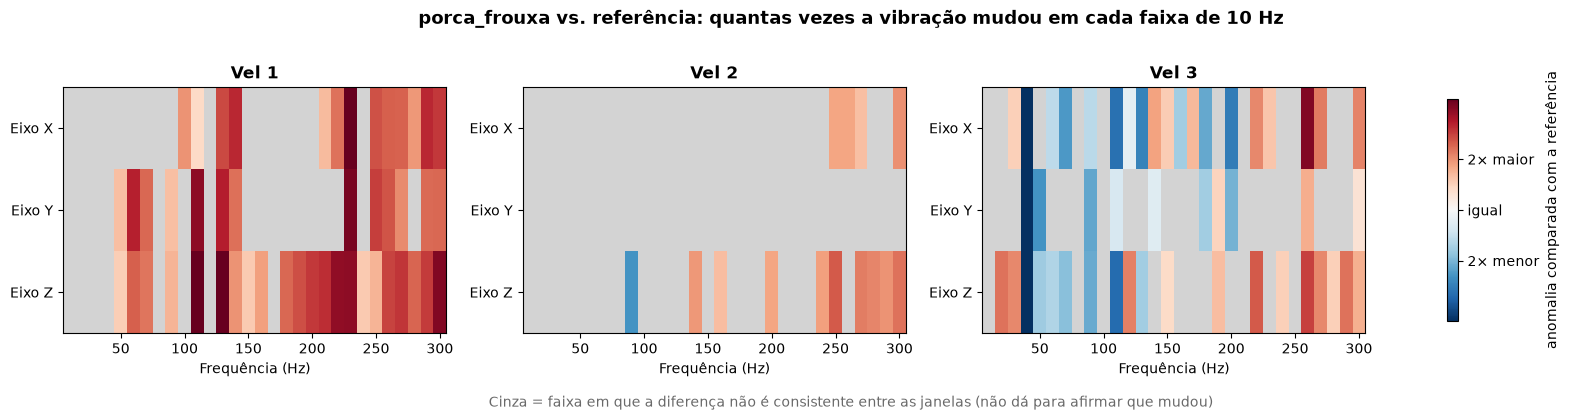

In [16]:
for condicao in condicoes_comparadas:
    plotar_mapa_simples(features, CONDICOES_REFERENCIA, condicao, velocidades)

### O que encontramos (mapa por faixa de 10 Hz)

* **Fita 1g:** na Vel 2 e na Vel 3 **quase todas as faixas** ficam vermelhas (maiores que no normal), em geral de 2 a mais de 10 vezes. Na **Vel 1** sobram poucas faixas coloridas, a maioria abaixo de 100 Hz.
* **Papel:** aumento consistente em grande parte das faixas acima de cerca de 130 Hz, em todas as velocidades. Os destaques são **70–80 Hz** nos eixos Y e Z na Vel 1 e **270–290 Hz** na Vel 3, com mais de 10 vezes.
* **Porca frouxa:**
  * **Vel 1:** várias faixas maiores, principalmente acima de 100 Hz.
  * **Vel 2:** quase tudo cinza, ou seja, sem diferença consistente.
  * **Vel 3:** mistura de faixas **maiores** e **menores** que no normal. Uma faixa menor não significa "a porca reduz a vibração"; pode ser só diferença entre as gravações.
* **Resumo visual:** fita forte e larga, papel forte nas altas frequências, porca fraca e dependente da velocidade.

## Passo 8 — Rotação 1X e harmônicas

**O que buscamos:** responder duas perguntas que o ventilador sem tacômetro nos obriga a medir pelo próprio sinal:

1. **A rotação é a mesma nas duas condições?** Se a anomalia mudar a rotação, parte da diferença entre as condições é só velocidade diferente, e não a falha.
2. **1X, 2X e 3X cresceram?** O pico em 1X (a rotação), e em 2X e 3X (harmônicas), é a assinatura clássica de desbalanceamento: massa a mais numa pá aumenta o 1X.

Em cada janela, o **1X** é o pico mais alto da soma dos três eixos dentro de `FAIXA_BUSCA_1X_HZ`. Como uma anomalia forte pode ter um pico de outra frequência mais alto que o 1X, a busca é feita em duas passadas: a primeira acha a rotação típica da base (mediana das janelas) e a segunda procura o pico só a até `DESVIO_MAX_1X_HZ` dela. A amplitude de **kX** é o maior pico a até `TOLERANCIA_HARMONICA_HZ` de k vezes o 1X.

* **8.1 — Tabela de rotação por base:** confira se o valor faz sentido para cada velocidade. Se o 1X estimado de uma base estiver estranho (por exemplo, caindo no dobro da rotação), ajuste `FAIXA_BUSCA_1X_HZ`.
* **8.2 — Rotação no tempo:** cada ponto é uma janela. Referência e anomalia no mesmo patamar indicam rotação igual.
* **8.3 — Amplitude em 1X, 2X e 3X:** boxplots como no Passo 5.
* **8.4 — Mapa de separação** de 1X, 2X e 3X, com o controle, como no Passo 5.

In [17]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))


def resumir_rotacao(features):
    """Rotação 1X (mediana, mínimo e máximo, em Hz) de cada base."""
    resumo = features.groupby("base", sort=False).agg(
        condicao=("condicao", "first"), velocidade=("velocidade", "first"),
        f1x_mediana_hz=("f1x_hz", "median"), f1x_min_hz=("f1x_hz", "min"), f1x_max_hz=("f1x_hz", "max"),
    )
    return resumo.sort_values(["velocidade", "condicao"])


def plotar_rotacao_no_tempo(features, condicoes_ref, condicao, velocidades):
    """Um painel por velocidade: rotação 1X de cada janela ao longo da base, referência e anomalia."""
    fig, axs = plt.subplots(1, len(velocidades), figsize=(6 * len(velocidades), 4), squeeze=False)
    for ax, velocidade in zip(axs[0], velocidades):
        grupos = ((COR_REFERENCIA, condicoes_ref, "referência"), (COR_COMPARADA, [condicao], condicao))
        for cor, condicoes, rotulo in grupos:
            janelas = selecionar_janelas(features, condicoes, velocidade)
            ax.scatter(janelas["janela"] * JANELA_S, janelas["f1x_hz"], s=14, color=cor, alpha=0.7, label=rotulo)
        ax.set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Tempo dentro da base (s)")
        ax.legend(fontsize=9)
    axs[0, 0].set_ylabel("Rotação 1X estimada (Hz)")
    fig.suptitle(f"Rotação 1X por janela — {condicao} vs. referência", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 8.1 — Rotação 1X estimada por base

In [18]:
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS]

display(resumir_rotacao(features).round(2))

,condicao,velocidade,f1x_mediana_hz,f1x_min_hz,f1x_max_hz
base,,,,,
fita_1g_vel_1,fita_1g,1,11.6,10.2,13.2
papel_vel_1,papel,1,12.4,11.2,13.6
porca_frouxa_vel_1,porca_frouxa,1,12.2,10.8,13.8
ventilador_normal_vel_1,ventilador_normal,1,12.4,10.8,13.6
fita_1g_vel_2,fita_1g,2,19.8,17.8,20.4
papel_vel_2,papel,2,18.0,15.6,18.8
porca_frouxa_vel_2,porca_frouxa,2,19.0,17.0,19.8
ventilador_normal_vel_2,ventilador_normal,2,18.6,16.8,19.4
fita_1g_vel_3,fita_1g,3,23.6,21.8,24.0


### O que encontramos (rotação 1X por base)

| Velocidade | Normal (mediana) | Faixa entre as condições |
| --- | --- | --- |
| Vel 1 | 12,4 Hz | 11,6 a 12,4 Hz |
| Vel 2 | 18,6 Hz | 18,0 a 19,8 Hz |
| Vel 3 | 22,6 Hz | 22,6 a 23,6 Hz |

* As três velocidades continuam bem separadas, mas **dentro de cada base** a rotação varia bastante: no normal Vel 1 ela vai de 10,8 a 13,6 Hz por causa do aquecimento.
* As diferenças entre condições (por exemplo, fita Vel 2 a 19,8 Hz contra 18,6 Hz no normal) **não têm um sentido único**: em algumas velocidades a falha gira mais rápido, em outras mais devagar. Como o aquecimento move a rotação mais do que isso, **não dá para usar a rotação como sinal de falha** com uma gravação por condição.

### 8.2 a 8.4 — Para cada condição comparada

==================== fita_1g vs. referência ====================


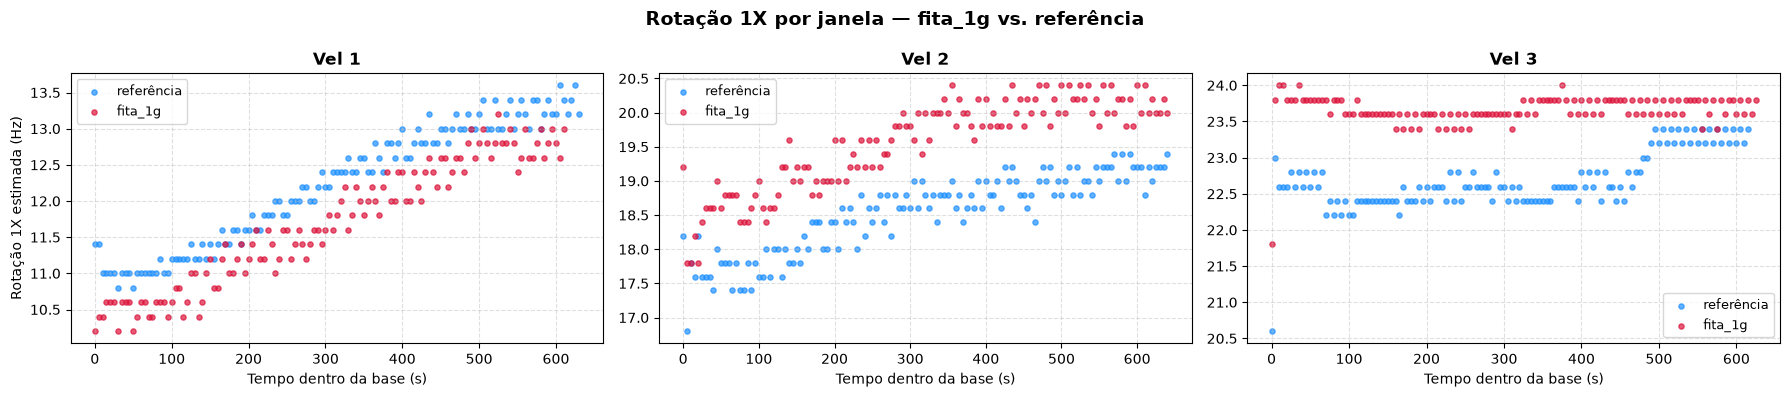

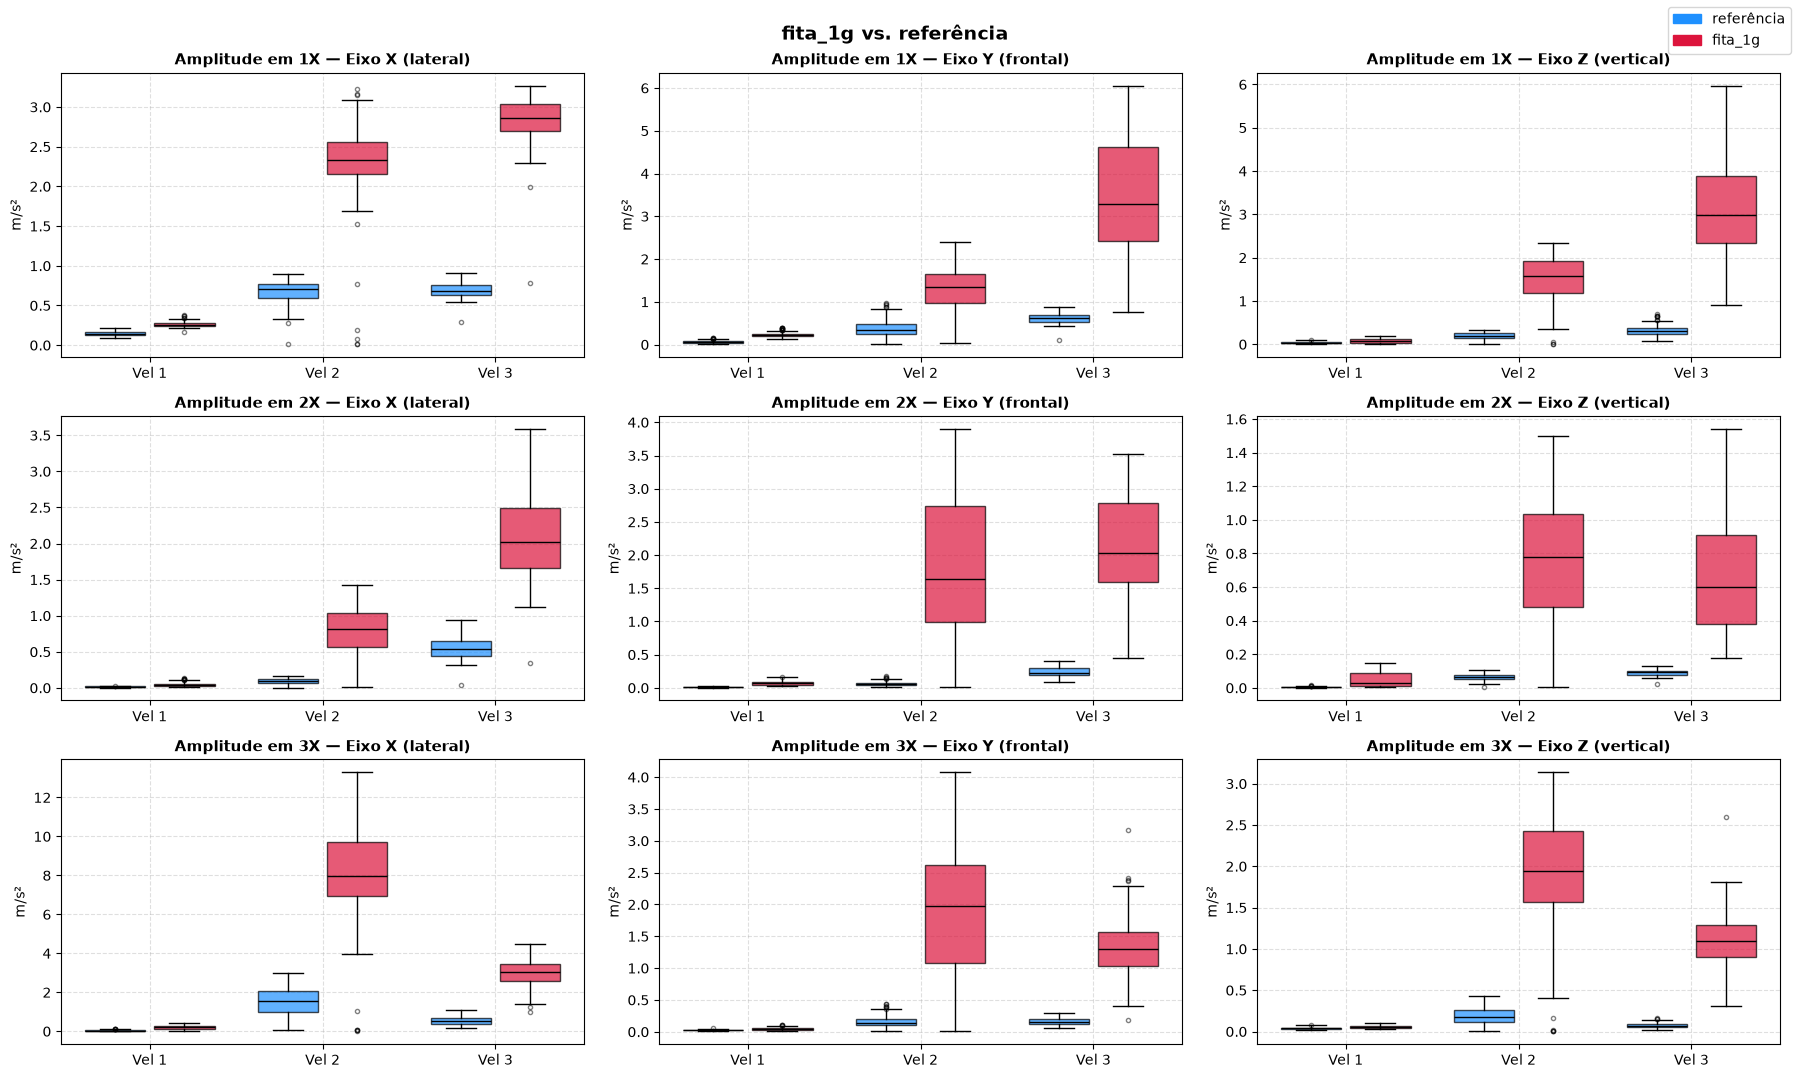

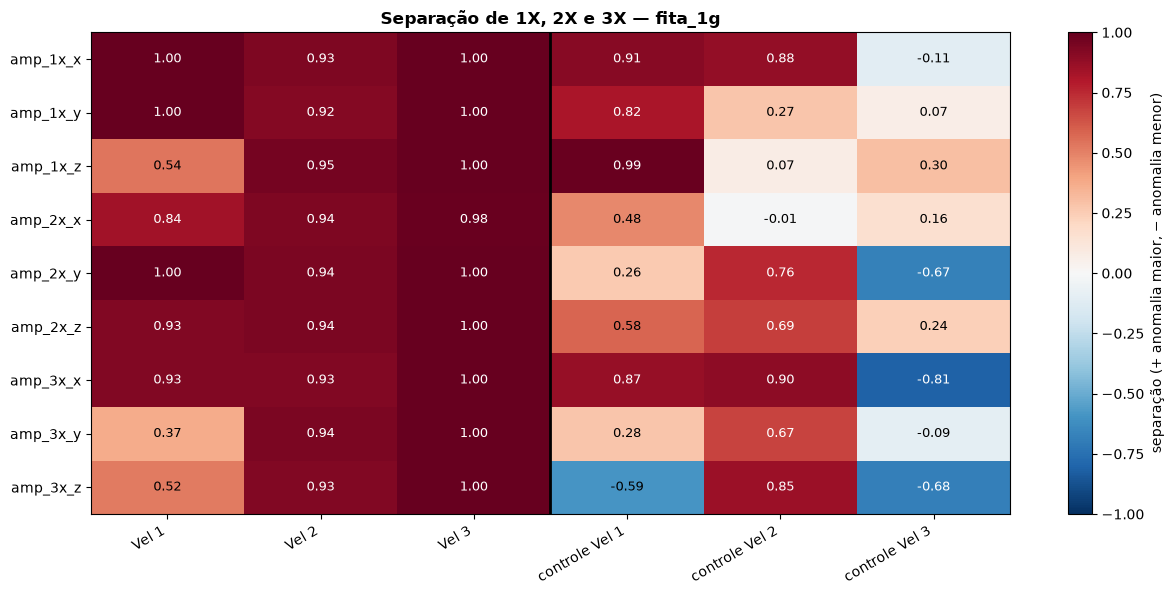

==================== papel vs. referência ====================


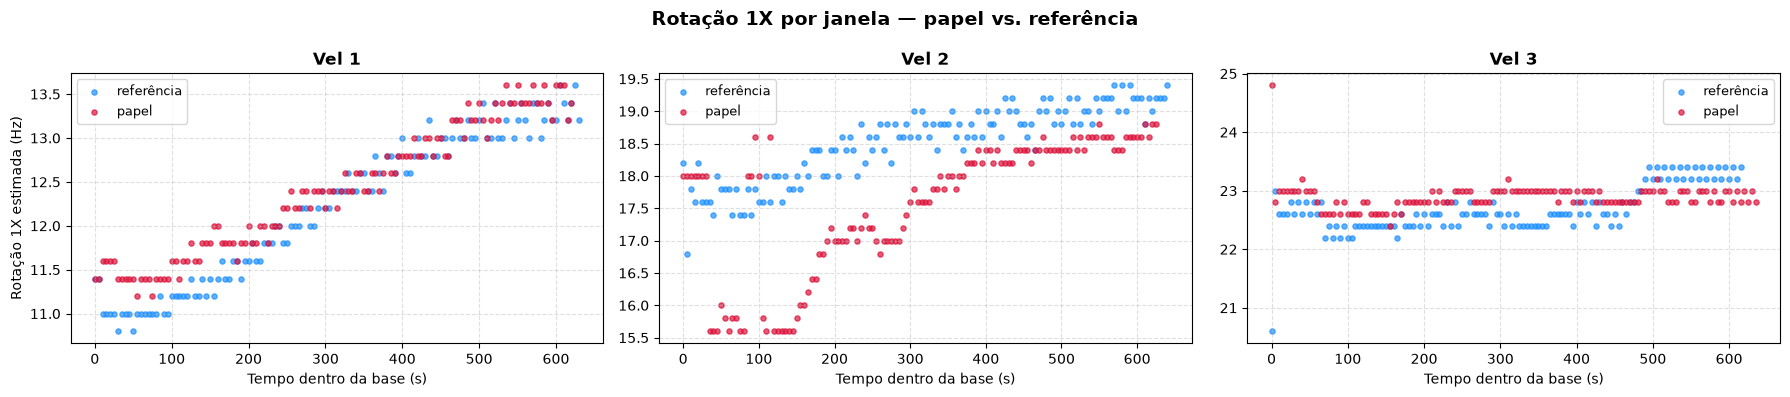

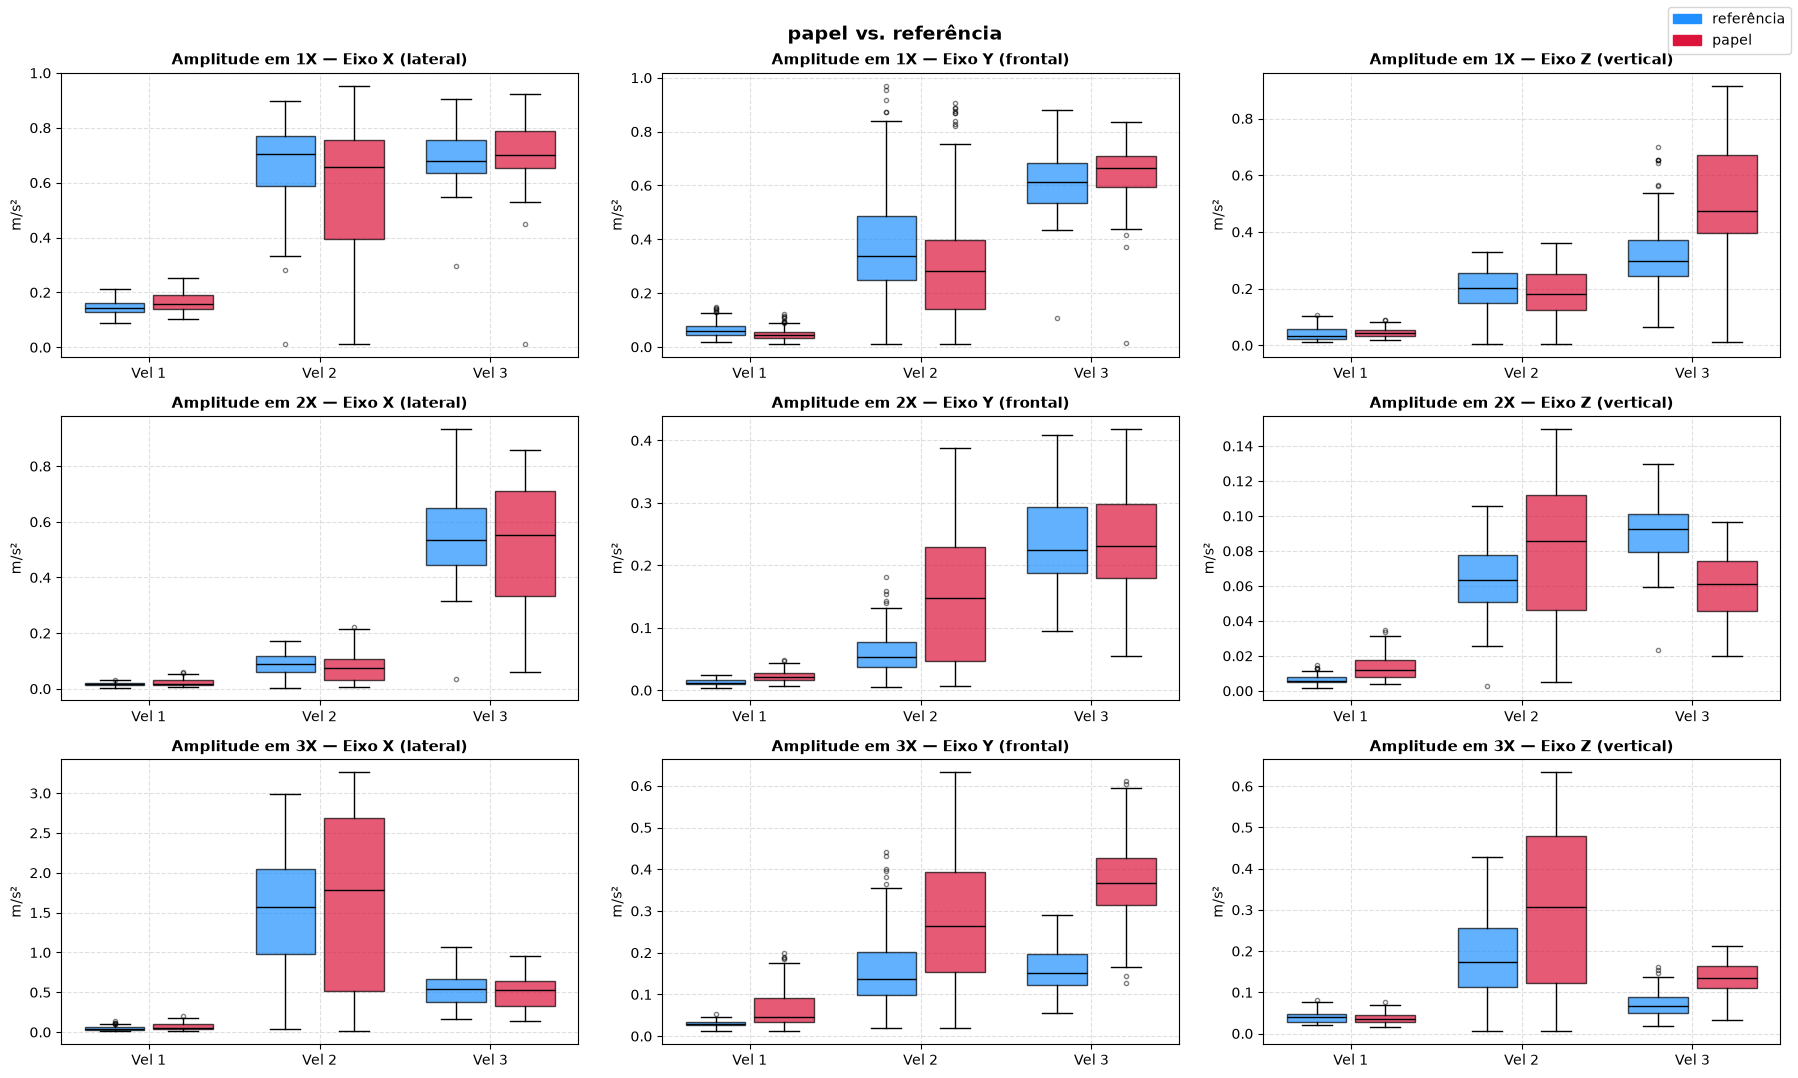

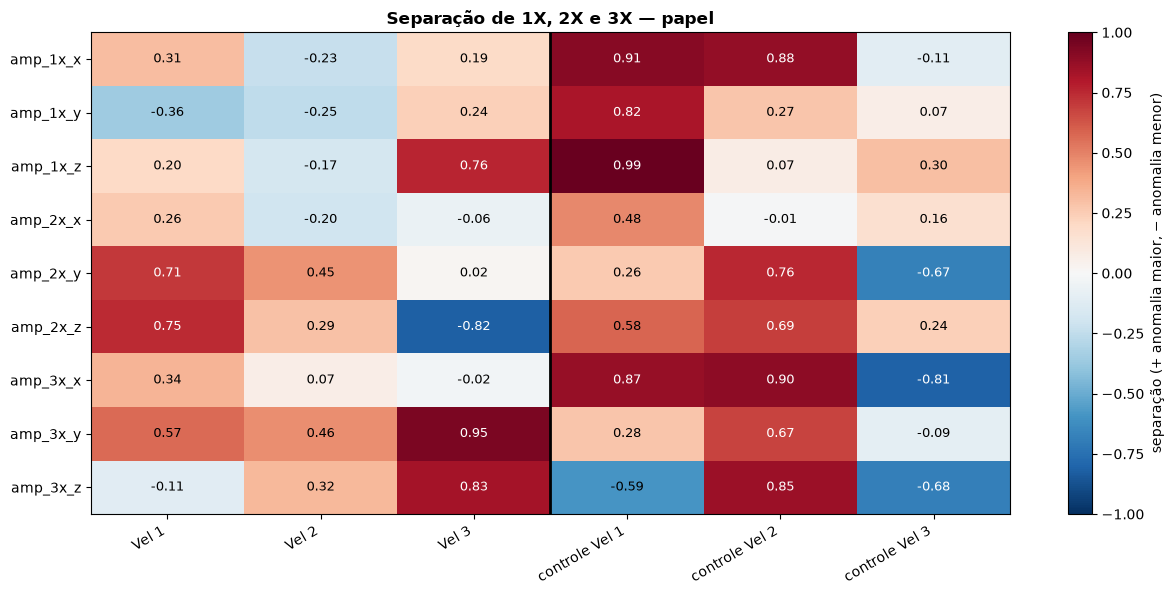

==================== porca_frouxa vs. referência ====================


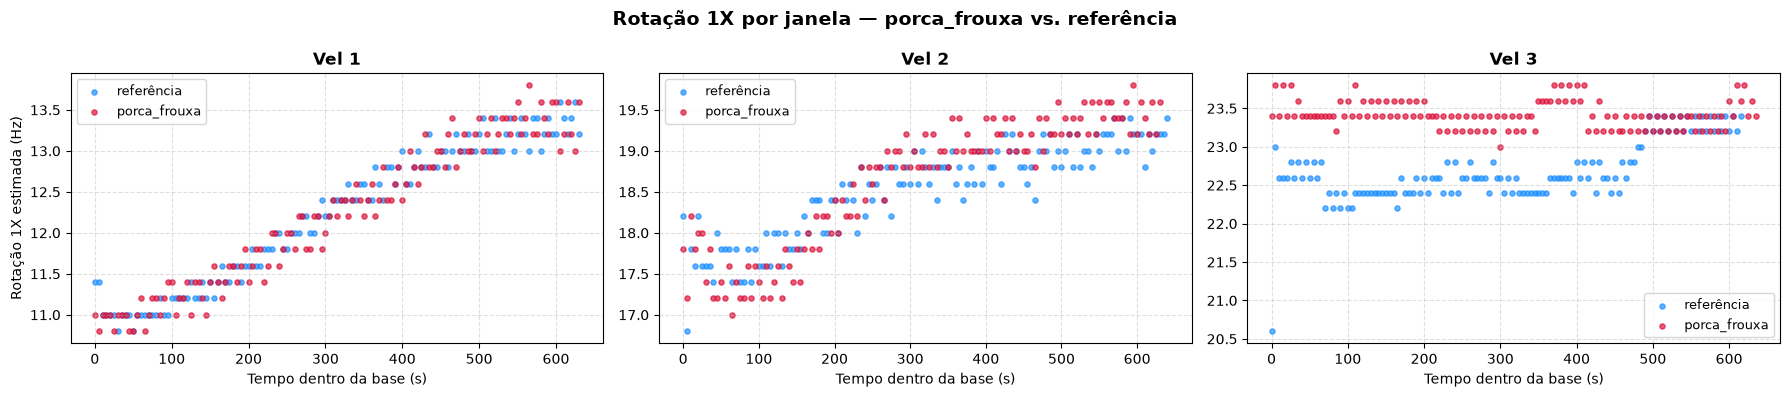

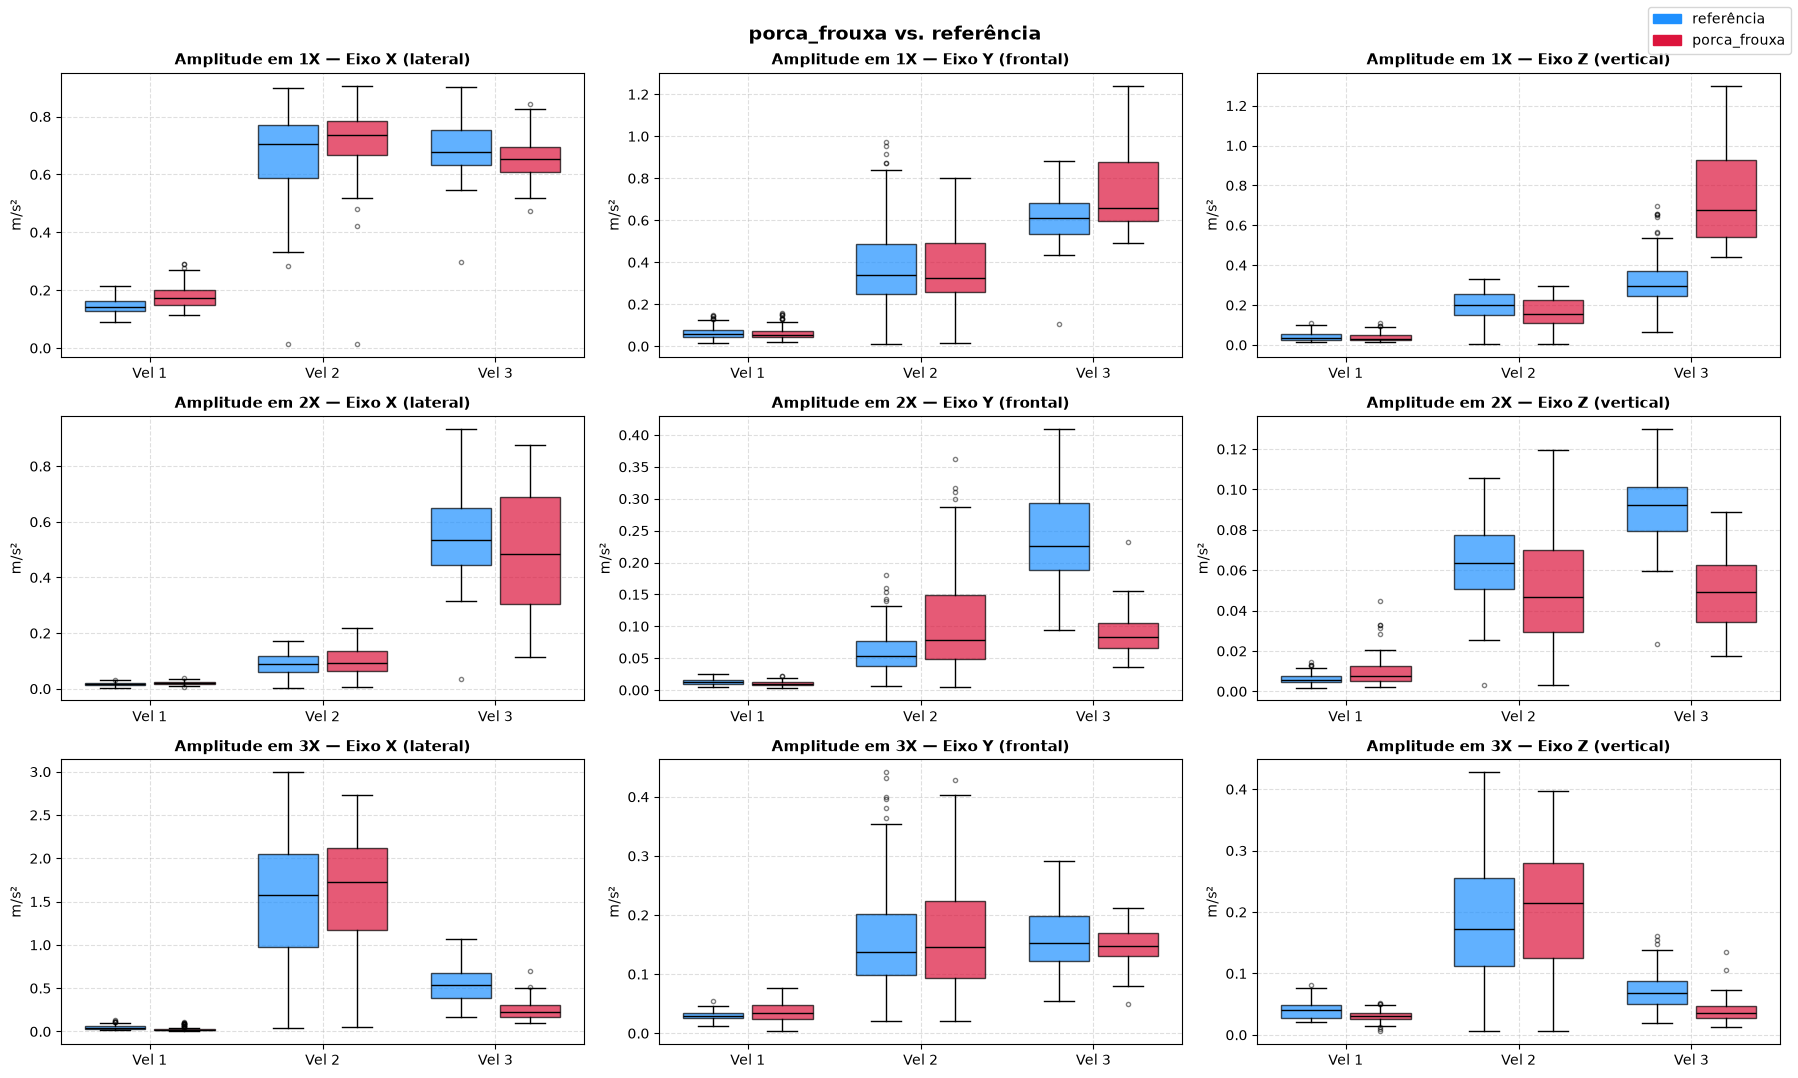

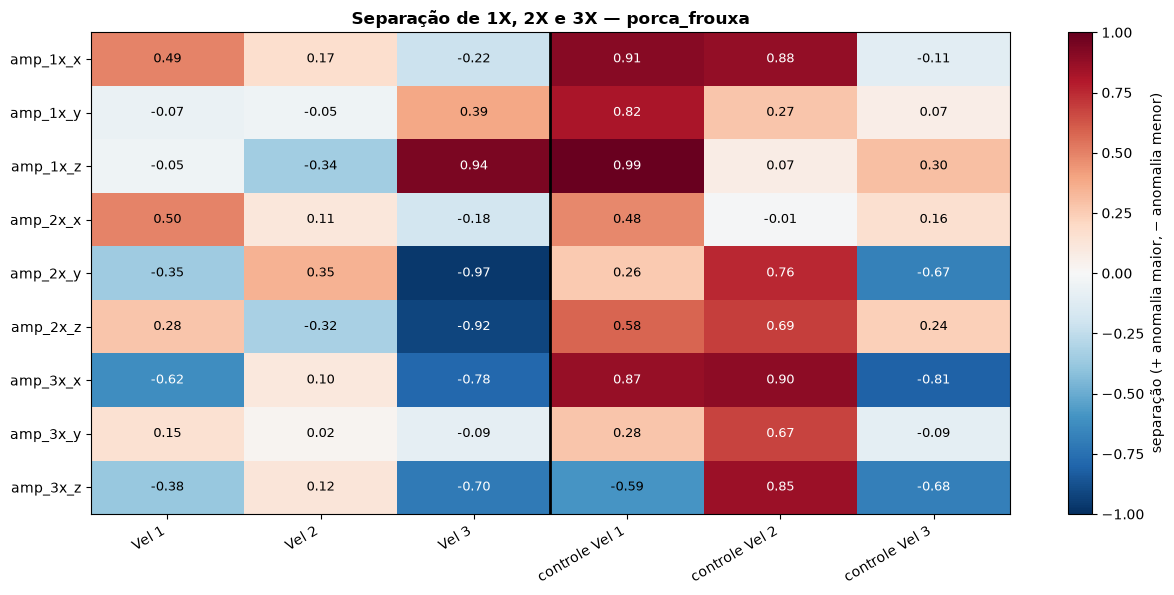

In [19]:
LINHAS_HARMONICAS = [(f"amp_{k}x", f"Amplitude em {k}X", UNIDADE) for k in range(1, N_HARMONICAS + 1)]

for condicao in condicoes_comparadas:
    print(f"==================== {condicao} vs. referência ====================")
    plotar_rotacao_no_tempo(features, CONDICOES_REFERENCIA, condicao, velocidades)
    plotar_boxplots_comparativo(features, CONDICOES_REFERENCIA, condicao, LINHAS_HARMONICAS, velocidades)

    matriz = montar_matriz_de_separacao(features, CONDICOES_REFERENCIA, condicao, COLUNAS_ROTACAO, velocidades)
    plotar_mapa_de_separacao(matriz, f"Separação de 1X, 2X e 3X — {condicao}", len(velocidades))

### O que encontramos (rotação no tempo e harmônicas)

* **Vel 1 e Vel 2:** a rotação **sobe ao longo de toda a gravação**, no normal e nas falhas. Na Vel 1 ela passa de cerca de 10,5–11 Hz no começo para cerca de 13–13,5 Hz no fim. É o aquecimento já visto no Notebook 01.
* **Vel 3:** fica praticamente estável, com degraus pequenos.
* **Harmônicas (`amp_kx`):** a **fita** aumenta 1X, 2X e 3X em todas as velocidades. **Papel e porca** quase não mexem nas harmônicas. Isso confirma o que os espectros mostraram: a fita é uma falha **de rotação** (desbalanceamento); papel e porca aparecem **fora** das harmônicas.
* **Consequência:** as features de amplitude harmônica são boas para distinguir **fita × (papel ou porca)**, mas pouco ajudam a distinguir **papel × porca**.

## Passo 9 — Resumo e controle

**O que buscamos:** reunir o que os passos anteriores mostraram em **uma tabela por condição**: quais features separam melhor a anomalia da referência em cada velocidade, e se essa separação **supera a variação natural do normal**.

Usamos todas as features: as 9 de tempo, as 90 de FFT, as 9 amplitudes em 1X, 2X e 3X e a própria rotação `f1x_hz`.

* **Tabela das melhores features:** as `N_TOP` com maior separação (em valor absoluto), com a separação, as medianas na referência e na anomalia e a separação do **controle** para a mesma feature.
* **Teto do controle:** a **maior** separação, entre todas as features, encontrada ao comparar a segunda com a primeira metade da referência. É o maior "falso sinal" que a variação natural do normal produz. Contamos quantas features da comparação **passam desse teto**. Quanto mais features passam, mais robusta é a diferença.
* **Atenção à porca frouxa:** no Notebook 01 ela ficou quase igual ao normal no tempo. Veja aqui se alguma feature (principalmente de FFT) supera o teto, e em quais velocidades.
* **Atenção ao aquecimento:** nos dados novos o normal muda dentro da própria gravação (Notebook 01, Passo 6), principalmente nas Vel 1 e 2. Isso aumenta o teto do controle e torna mais difícil uma feature superá-lo.

**Se o controle de uma velocidade for alto**, a própria referência mudou ao longo da gravação (deriva). Confira no Passo 8.2 se a rotação 1X subiu ou desceu durante a base: nesse caso, parte da diferença entre normal e anomalia pode ser só rotação diferente, e vale gravar essa velocidade de novo ou compará-la só nas janelas em que a rotação coincide.

O teto é uma **régua de referência**, não um teste estatístico: com mais de 100 features, o maior valor do controle já é, por construção, um valor alto. Os testes ficam para o Notebook 03.

In [20]:
def resumir_melhores_features(features, condicoes_ref, condicao, colunas, velocidades, n_top=N_TOP):
    """Melhores features de cada velocidade e o teto de variação natural da referência.

    Devolve (melhores, tetos). 'melhores' tem as n_top features de maior separação por velocidade.
    'tetos' tem, por velocidade, a maior separação do controle e quantas features a superam.
    """
    linhas_melhores, linhas_tetos = [], []
    for velocidade in velocidades:
        ref = selecionar_janelas(features, condicoes_ref, velocidade)
        comp = selecionar_janelas(features, [condicao], velocidade)
        if len(ref) == 0 or len(comp) == 0:
            continue
        separacao = calcular_separacao(comp, ref, colunas)
        controle = calcular_separacao_controle(ref, colunas)
        teto = controle.abs().max()
        for feature in separacao.abs().sort_values(ascending=False).head(n_top).index:
            linhas_melhores.append({
                "velocidade": velocidade,
                "feature": feature,
                "separacao": separacao[feature],
                "mediana_referencia": ref[feature].median(),
                "mediana_anomalia": comp[feature].median(),
                "controle": controle[feature],
            })
        linhas_tetos.append({
            "velocidade": velocidade,
            "teto_do_controle": teto,
            "features_acima_do_teto": int((separacao.abs() > teto).sum()),
            "total_de_features": len(colunas),
        })
    return pd.DataFrame(linhas_melhores), pd.DataFrame(linhas_tetos)

In [21]:
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO + ["f1x_hz"]

for condicao in condicoes_comparadas:
    melhores, tetos = resumir_melhores_features(features, CONDICOES_REFERENCIA, condicao, COLUNAS_TODAS, velocidades)
    print(f"==================== {condicao} vs. referência ====================")
    print("Teto do controle e features que o superam:")
    display(tetos.set_index("velocidade").round(2))
    print(f"As {N_TOP} features com maior separação em cada velocidade:")
    display(melhores.set_index(["velocidade", "feature"]).round(3))

==================== fita_1g vs. referência ====================
Teto do controle e features que o superam:


,teto_do_controle,features_acima_do_teto,total_de_features
velocidade,,,
1,1.00,5,109
2,0.97,29,109
3,0.83,95,109


As 5 features com maior separação em cada velocidade:


separacao  mediana_referencia  mediana_anomalia  \
velocidade feature                                                            
1          fft_005_015Hz_y      0.999               0.059             0.220   
           amp_1x_y             0.999               0.059             0.220   
           amp_2x_y             0.999               0.012             0.067   
           fft_005_015Hz_x      0.997               0.142             0.252   
           amp_1x_x             0.997               0.142             0.252   
2          kurt_z               1.000              -0.219             2.256   
           pico_z               1.000               1.974            23.990   
           std_z                0.999               0.564             5.483   
           fft_015_025Hz_z      0.998               0.202             1.574   
           std_y                0.995               1.316             7.335   
3          std_x                1.000               1.159             4.419   
           std_y                1.000               0.957             5.154   
           std_z                1.000               0.569             3.559   
           pico_y               1.000               3.335            18.347   
           pico_x               1.000               4.316            14.855   

                            controle  
velocidade feature                    
1          fft_005_015Hz_y     0.818  
           amp_1x_y            0.818  
           amp_2x_y            0.264  
           fft_005_015Hz_x     0.907  
           amp_1x_x            0.907  
2          kurt_z              0.224  
           pico_z              0.834  
           std_z               0.946  
           fft_015_025Hz_z     0.070  
           std_y               0.973  
3          std_x              -0.827  
           std_y              -0.720  
           std_z              -0.122  
           pico_y             -0.386  
           pico_x             -0.690

==================== papel vs. referência ====================
Teto do controle e features que o superam:


,teto_do_controle,features_acima_do_teto,total_de_features
velocidade,,,
1,1.00,14,109
2,0.97,12,109
3,0.83,67,109


... (2 outputs left out)

==================== porca_frouxa vs. referência ====================
Teto do controle e features que o superam:


,teto_do_controle,features_acima_do_teto,total_de_features
velocidade,,,
1,1.00,10,109
2,0.97,1,109
3,0.83,19,109


As 5 features com maior separação em cada velocidade:


separacao  mediana_referencia  mediana_anomalia  \
velocidade feature                                                            
1          std_z                1.000               0.239             0.556   
           pico_z               1.000               0.779             2.036   
           fft_225_235Hz_x      1.000               0.031             0.146   
           fft_105_115Hz_y      1.000               0.048             0.185   
           fft_125_135Hz_y      1.000               0.116             0.380   
2          fft_135_145Hz_z      0.999               0.087             0.167   
           fft_245_255Hz_z      0.869               0.012             0.030   
           fft_285_295Hz_z      0.857               0.010             0.020   
           fft_255_265Hz_x      0.819               0.049             0.089   
           fft_275_285Hz_z      0.778               0.013             0.027   
3          fft_255_265Hz_x      1.000               0.061             0.247   
           fft_255_265Hz_z      1.000               0.048             0.136   
           fft_215_225Hz_z      1.000               0.055             0.140   
           amp_2x_y            -0.967               0.225             0.084   
           fft_135_145Hz_x      0.961               0.075             0.138   

                            controle  
velocidade feature                    
1          std_z               0.706  
           pico_z              0.666  
           fft_225_235Hz_x    -0.176  
           fft_105_115Hz_y    -0.778  
           fft_125_135Hz_y     0.375  
2          fft_135_145Hz_z    -0.201  
           fft_245_255Hz_z     0.347  
           fft_285_295Hz_z     0.314  
           fft_255_265Hz_x     0.207  
           fft_275_285Hz_z    -0.097  
3          fft_255_265Hz_x     0.543  
           fft_255_265Hz_z     0.429  
           fft_215_225Hz_z     0.462  
           amp_2x_y           -0.674  
           fft_135_145Hz_x    -0.018

### 9.1 — Quem define o teto do controle?

O teto do controle é a **maior** separação entre a segunda e a primeira metade da própria condição. Se ele é alto, quase nenhuma feature consegue superá-lo, e o Passo 9 fica "rigoroso demais". Nos dados novos isso é esperado, porque cada gravação começa com o motor frio e a rotação sobe com o aquecimento (Notebook 01): a segunda metade fica diferente da primeira **sem nenhuma falha envolvida**.

A tabela abaixo mostra, para cada condição e velocidade, **as 3 features que mais mudam dentro da própria gravação** (as que definem o teto) e quantas features mudam mais de 0,8 só com o passar do tempo.

* Se aparecer **`f1x_hz`** ou as faixas da rotação (5–25 Hz) no topo, o teto está sendo definido pelo **aquecimento**.
* Uma condição com muitas features acima de 0,8 no controle **não é estável** ao longo da gravação. Isso não é uma falha do método: é uma informação sobre os dados que o Notebook 05 precisa respeitar (blocos no tempo e teste em outra sessão).

In [22]:
def mostrar_quem_define_o_teto(features, condicoes, colunas, velocidades, n=3, limite=0.8):
    """Para cada condição e velocidade: as n features com maior |separação do controle| e quantas passam do limite."""
    linhas = []
    for condicao in condicoes:
        for velocidade in velocidades:
            janelas = selecionar_janelas(features, [condicao], velocidade)
            if len(janelas) == 0:
                continue
            controle = calcular_separacao_controle(janelas, colunas).abs().sort_values(ascending=False)
            linhas.append({"condicao": condicao, "velocidade": velocidade,
                           "teto": round(controle.iloc[0], 3),
                           "features que definem o teto": ", ".join(f"{f} ({v:.2f})" for f, v in controle.head(n).items()),
                           f"features com |controle| > {limite}": int((controle > limite).sum())})
    return pd.DataFrame(linhas).set_index(["condicao", "velocidade"])

In [23]:
quem_define = mostrar_quem_define_o_teto(features, CONDICOES_REFERENCIA + list(condicoes_comparadas), COLUNAS_TODAS, velocidades)
with pd.option_context("display.max_colwidth", None):
    display(quem_define)

teto  \
condicao          velocidade          
ventilador_normal 1           0.996   
                  2           0.973   
                  3           0.827   
fita_1g           1           0.996   
                  2           0.957   
                  3           0.652   
papel             1           0.984   
                  2           0.998   
                  3           0.917   
porca_frouxa      1           0.992   
                  2           0.976   
                  3           0.757   

                                                                         features que definem o teto  \
condicao          velocidade                                                                           
ventilador_normal 1                           f1x_hz (1.00), fft_005_015Hz_z (0.99), amp_1x_z (0.99)   
                  2                                        std_y (0.97), pico_y (0.97), std_x (0.96)   
                  3                            std_x (0.83), fft_095_105Hz_y (0.81), amp_3x_x (0.81)   
fita_1g           1                              f1x_hz (1.00), fft_175_185Hz_y (0.98), std_x (0.98)   
                  2                    f1x_hz (0.96), fft_215_225Hz_x (0.92), fft_075_085Hz_x (0.89)   
                  3           fft_165_175Hz_y (0.65), fft_165_175Hz_z (0.62), fft_285_295Hz_y (0.62)   
papel             1                                     f1x_hz (0.98), std_y (0.98), amp_3x_x (0.97)   
                  2                                amp_3x_x (1.00), amp_3x_z (1.00), amp_2x_y (1.00)   
                  3                                         std_y (0.92), std_z (0.90), std_x (0.89)   
porca_frouxa      1                    f1x_hz (0.99), fft_165_175Hz_y (0.96), fft_215_225Hz_x (0.96)   
                  2                              std_z (0.98), f1x_hz (0.96), fft_035_045Hz_x (0.95)   
                  3           fft_215_225Hz_x (0.76), fft_095_105Hz_y (0.54), fft_115_125Hz_x (0.53)   

                              features com |controle| > 0.8  
condicao          velocidade                                 
ventilador_normal 1                                      21  
                  2                                      21  
                  3                                       3  
fita_1g           1                                      43  
                  2                                      15  
                  3                                       0  
papel             1                                      23  
                  2                                      28  
                  3                                       4  
porca_frouxa      1                                      21  
                  2                                      22  
                  3                                       0

### O que encontramos (resumo das features)

**Features acima do teto do controle (de 109):**

| Falha | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| Fita 1g | 5 | 29 | 95 |
| Papel | 14 | 12 | 67 |
| Porca frouxa | 10 | **1** | 19 |

* **Todas as falhas passam do teto em todas as velocidades.** O caso mais frágil é a **porca na Vel 2**: só **1 feature** (`fft_135_145Hz_z`, separação 0,999) supera o teto.
* **O teto está muito alto nas Vel 1 e 2 (9.1):** no normal Vel 1 ele vale 0,996, definido por `f1x_hz`. Isso quer dizer que **só o aquecimento** separa a primeira e a segunda metade da gravação quase perfeitamente. No normal Vel 1 e Vel 2, **21 features** mudam mais de 0,8 só com o passar do tempo. Por isso os números das Vel 1 e 2 parecem pequenos: o critério ficou muito exigente, não é que as falhas sejam fracas.
* **Comparação com os dados antigos:** lá a fita na Vel 1 também foi o caso difícil. Aqui ela continua sendo, por dois motivos: física (força centrífuga pequena) e aquecimento (teto alto).
* **Melhores features por falha:**
  * **Fita:** 1X e as faixas da rotação na Vel 1; `kurt_z`, `pico_z` e `std_z` na Vel 2; `std` e `pico` na Vel 3.
  * **Papel:** `std` e `pico` em todas as velocidades, mais as faixas acima de 245 Hz no eixo Z na Vel 2.
  * **Porca:** `std_z`, `pico_z` e faixas de 105–235 Hz na Vel 1; quase só faixas de FFT nas Vel 2 e 3.
* **Para os próximos notebooks:**
  1. As features que mudam com o aquecimento (`f1x_hz`, as faixas de 5–25 Hz) separam a primeira e a segunda metade de **qualquer** base. Um modelo pode aprender "começo ou fim da gravação" em vez de "falha". A divisão em blocos no tempo do Notebook 05 é obrigatória.
  2. A porca na Vel 2 é o candidato natural a **erro do modelo**.

## Passo 10 — Falha contra falha: dá para saber **qual** é a falha?

**O que buscamos:** até aqui cada falha foi comparada com o normal, que é a pergunta do **modelo 1** (detecção: "está com falha?"). Agora comparamos **as falhas entre si**, que é a pergunta do **modelo 2** (diagnóstico: "qual é a falha?"). Como combinado, não juntamos falhas num grupo só: trocamos a **referência** e comparamos uma falha com outra, sempre na mesma velocidade.

### 10.1 — Mapa de distinção entre todas as condições

Um mapa por velocidade. Cada célula responde: **comparando a condição da coluna com a da linha, quantas das features separam as duas acima do teto do controle?** O teto é calculado com a condição da **linha** (a segunda metade dela contra a primeira), como no Passo 9.

* **Número alto (verde escuro):** as duas condições se distinguem por muitas features. É fácil diferenciá-las.
* **Número perto de zero:** quase nenhuma feature supera a variação natural. Diferenciar as duas vai ser difícil.
* **A primeira linha (normal)** repete o Passo 9: é a detecção de cada falha.
* **O mapa não é simétrico:** a linha de "papel" usa o teto do papel e a linha de "fita" usa o teto da fita. Uma condição que varia muito sozinha (teto alto) fica mais difícil de superar.

### 10.2 — Tabela dos pares de falhas

Para cada par de falhas e velocidade: o teto do controle, quantas features o superam e qual feature separa melhor o par, com as medianas nas duas falhas.

In [24]:
def montar_matriz_de_distincao(features, condicoes, colunas, velocidade):
    """Para cada par (referência na linha, comparada na coluna): quantas features superam o teto do controle da referência."""
    matriz = pd.DataFrame(np.nan, index=condicoes, columns=condicoes)
    for ref in condicoes:
        janelas_ref = selecionar_janelas(features, [ref], velocidade)
        if len(janelas_ref) == 0:
            continue
        teto = calcular_separacao_controle(janelas_ref, colunas).abs().max()
        for comp in condicoes:
            janelas_comp = selecionar_janelas(features, [comp], velocidade)
            if comp == ref or len(janelas_comp) == 0:
                continue
            matriz.loc[ref, comp] = int((calcular_separacao(janelas_comp, janelas_ref, colunas).abs() > teto).sum())
    return matriz


def plotar_matrizes_de_distincao(features, condicoes, colunas, velocidades):
    """Um mapa por velocidade: quantas das features separam cada par de condições acima do teto do controle."""
    fig, axs = plt.subplots(1, len(velocidades), figsize=(5.6 * len(velocidades), 5), squeeze=False)
    for ax, velocidade in zip(axs[0], velocidades):
        matriz = montar_matriz_de_distincao(features, condicoes, colunas, velocidade)
        ax.imshow(matriz.to_numpy(dtype=float), cmap="Greens", vmin=0, vmax=len(colunas))
        for i in range(len(condicoes)):
            for j in range(len(condicoes)):
                valor = matriz.iat[i, j]
                texto = "—" if np.isnan(valor) else f"{int(valor)}"
                ax.text(j, i, texto, ha="center", va="center", fontsize=11,
                        color="white" if (not np.isnan(valor) and valor > 0.6 * len(colunas)) else "black")
        ax.set_xticks(range(len(condicoes)))
        ax.set_xticklabels(condicoes, rotation=30, ha="right", fontsize=9)
        ax.set_yticks(range(len(condicoes)))
        ax.set_yticklabels(condicoes, fontsize=9)
        ax.set_xlabel("comparada")
        ax.set_ylabel("referência (fornece o teto do controle)")
        ax.grid(False)
        ax.set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
    fig.suptitle(f"Quantas das {len(colunas)} features separam cada par acima do teto do controle", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


def resumir_pares_de_falhas(features, falhas, colunas, velocidades):
    """Para cada par de falhas e velocidade: teto do controle, features acima do teto e a melhor feature."""
    linhas = []
    for i, falha_a in enumerate(falhas):
        for falha_b in falhas[i + 1:]:
            melhores, tetos = resumir_melhores_features(features, [falha_a], falha_b, colunas, velocidades, n_top=1)
            for _, teto in tetos.iterrows():
                melhor = melhores[melhores["velocidade"] == teto["velocidade"]].iloc[0]
                linhas.append({"par": f"{falha_a} × {falha_b}", "velocidade": int(teto["velocidade"]),
                               "teto do controle": teto["teto_do_controle"],
                               "features acima do teto": int(teto["features_acima_do_teto"]),
                               "melhor feature": melhor["feature"], "separação": melhor["separacao"],
                               "mediana na 1ª falha": melhor["mediana_referencia"], "mediana na 2ª falha": melhor["mediana_anomalia"]})
    return pd.DataFrame(linhas)

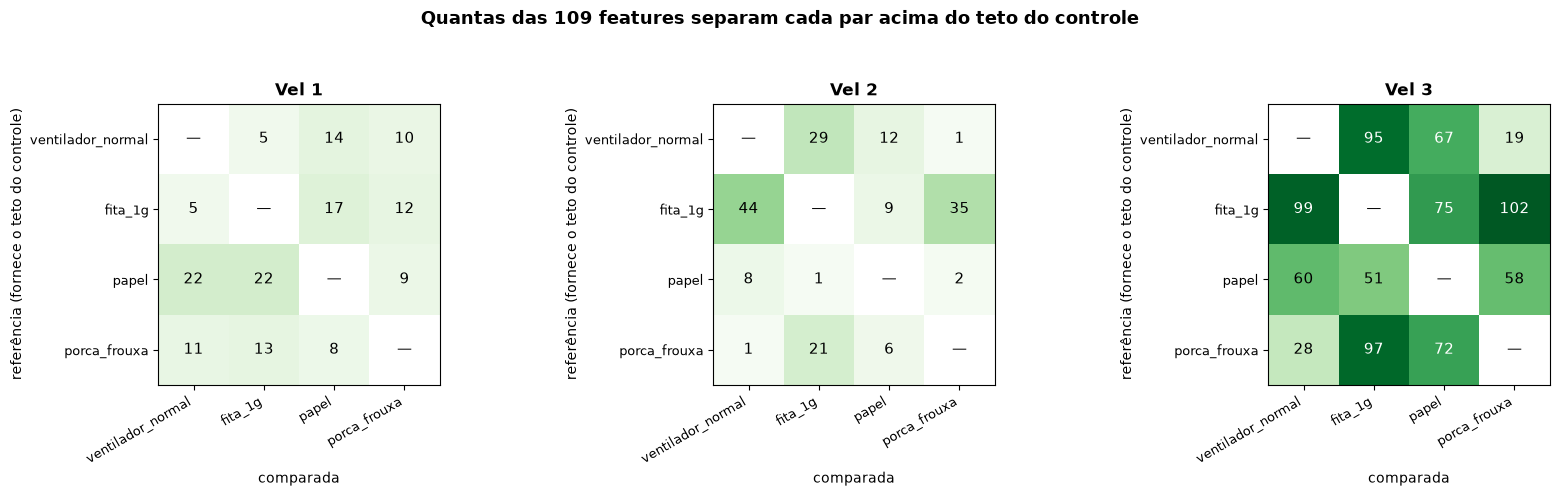

teto do controle  features acima do teto  \
par                    velocidade                                             
fita_1g × papel        1                      0.996                      17   
                       2                      0.957                       9   
                       3                      0.652                      75   
fita_1g × porca_frouxa 1                      0.996                      12   
                       2                      0.957                      35   
                       3                      0.652                     102   
papel × porca_frouxa   1                      0.984                       9   
                       2                      0.998                       2   
                       3                      0.917                      58   

                                    melhor feature  separação  \
par                    velocidade                               
fita_1g × papel        1                     std_y      1.000   
                       2           fft_015_025Hz_z     -0.998   
                       3                     std_x     -1.000   
fita_1g × porca_frouxa 1           fft_125_135Hz_x      1.000   
                       2           fft_015_025Hz_z     -1.000   
                       3                     std_x     -1.000   
papel × porca_frouxa   1                     std_x     -1.000   
                       2                     std_z     -1.000   
                       3                     std_x     -1.000   

                                   mediana na 1ª falha  mediana na 2ª falha  
par                    velocidade                                            
fita_1g × papel        1                         0.914                2.066  
                       2                         1.574                0.180  
                       3                         4.419                2.166  
fita_1g × porca_frouxa 1                         0.094                0.340  
                       2                         1.574                0.155  
                       3                         4.419                1.065  
papel × porca_frouxa   1                         1.308                0.664  
                       2                         1.708                0.649  
                       3                         2.166                1.065

In [25]:
FALHAS = list(condicoes_comparadas)
plotar_matrizes_de_distincao(features, CONDICOES_REFERENCIA + FALHAS, COLUNAS_TODAS, velocidades)

pares = resumir_pares_de_falhas(features, FALHAS, COLUNAS_TODAS, velocidades)
display(pares.set_index(["par", "velocidade"]).round(3))

### O que encontramos (falha contra falha)

**Features acima do teto, por par:**

| Par | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| Fita × papel | 17 | 9 | 75 |
| Fita × porca | 12 | 35 | 102 |
| Papel × porca | 9 | **2** | 58 |

* **Todos os pares têm pelo menos uma feature que separa perfeitamente** (separação de 1,00 em módulo) em todas as velocidades. Exemplos:
  * **Papel × porca:** `std_x` na Vel 1 (1,31 contra 0,66) e `std_z` na Vel 2 (1,71 contra 0,65).
  * **Fita × papel e fita × porca na Vel 2:** a faixa 15–25 Hz do eixo Z, que é a 1X dessa velocidade (fita 1,57 contra 0,18 do papel e 0,16 da porca).
* **Par mais difícil: papel × porca na Vel 2**, com só 2 features acima do teto. Faz sentido: nenhuma das duas mexe na rotação e as duas aparecem como aumento de vibração fora das harmônicas.
* **Par mais fácil: fita × porca na Vel 3**, com 102 de 109 features.
* **O mapa não é simétrico, e isso é informativo:**
  * Na linha do **papel** os números são menores na Vel 2 (8, 1, 2), porque o teto do papel na Vel 2 é 0,998: o próprio papel muda muito entre o começo e o fim da gravação (`amp_3x`).
  * O papel é uma **falha instável**, o que é coerente com uma folha que se mexe e muda de posição.
* **Resposta à pergunta do passo:** nesta sessão, **dá para distinguir as três falhas entre si** em todas as velocidades, e o tipo de diferença faz sentido físico:
  * a fita mexe nas **harmônicas da rotação**;
  * o papel aumenta a vibração **larga e de alta frequência**;
  * a porca muda **pouco e em faixas específicas**.
* **Cuidado com a interpretação:** como existe uma gravação por condição, uma separação perfeita aqui também pode ser **"gravação A × gravação B"**. A prova de que é a falha, e não a sessão, só vem testando em outra sessão (Notebook 05). Por enquanto isso só é possível para fita e normal, que existem nos dados antigos.

## Conclusão do Notebook 02 (dados novos)

1. **Detecção (normal × falha):** as três falhas superam o teto do controle em todas as velocidades. Em força: **fita > papel > porca**. O caso frágil é a **porca na Vel 2**, com 1 feature acima do teto.
2. **Diagnóstico (falha × falha):** as três falhas se distinguem entre si nesta sessão. O par mais difícil é **papel × porca na Vel 2**.
3. **Assinaturas físicas:**
   * **fita:** 1X e harmônicas, crescendo com a velocidade (desbalanceamento);
   * **papel:** vibração larga e de alta frequência;
   * **porca:** mudanças pequenas e espalhadas, dependentes da velocidade.
4. **Aquecimento:** nas Vel 1 e 2 ele faz a rotação subir ao longo da gravação e eleva o teto do controle até cerca de 0,97–1,00. Isso deixa o Passo 9 muito exigente nessas velocidades e cria um risco real de o modelo aprender "começo ou fim da gravação".
5. **Linhas em 120 e 240 Hz:** aparecem em todas as condições; não são falha (origem a confirmar com o orientador).
6. **Hipótese a confirmar:** uma possível ressonância perto de 57 Hz amplificaria a 3X na Vel 2.
7. **Limite principal:** **uma gravação por condição e velocidade**. Toda separação deste notebook pode conter efeito de sessão.

**Próximo passo:** o Notebook 03 (estatística) com os dados novos: distribuições, log e autocorrelação das janelas. A autocorrelação vai importar ainda mais aqui por causa do aquecimento.

## O que conferir antes de seguir para o Notebook 03

* [ ] **Passo 2:** toda velocidade comparada existe também na referência.
* [ ] **Passo 5:** as features de tempo que mudam estão identificadas, e a cor forte **some** nas colunas de controle.
* [ ] **Passos 6 e 7:** as faixas de frequência onde a anomalia aparece estão anotadas, por eixo e velocidade.
* [ ] **Passo 8:** a rotação 1X estimada faz sentido em cada velocidade, e é a mesma na referência e na anomalia.
* [ ] **Passo 9:** em cada velocidade há features acima do teto do controle. Se não houver, anote qual velocidade ficou sem separação.
* [ ] **Passo 10:** os pares de falhas mais difíceis de distinguir estão anotados.

**Próximo passo:** Notebook 03, a **análise estatística** (Shapiro-Wilk e assimetria), com as mesmas bases e a mesma tabela de features.